# C02r — Discovery-gated punctuation intervention

**Question:** after Unique + sentence-mean treatment, does restricting punctuation intervention to the top 30 AI-ward contribution gaps preserve helpful features while removing residual confounds?

Run from top to bottom in the existing research environment. Defaults: 200 non-poetry RAID texts, genre-balanced selection, 50% discovery / 50% evaluation assigned before generation. Human references are RAID training texts of the same genre. Discovery ranks signed frozen-tree contribution gaps; only positive top-30 features qualify. Comma is always eligible; periods, question marks and exclamation marks are protected during punctuation editing. Nontrivial marks are processed first. No detector-score acceptance criterion.

This notebook embeds the existing Unique controller and exact FZ118 extractor. The sentence controller targets **WPS/CPS means only**, with expanded clause splits and paired boundary shifts. The punctuation implementation enumerates local vertices anew after each accepted edit; exhausted means exhausted **under these explicit rules**, not every possible English rewrite. Likelihood ranks candidates without a punctuation cutoff. Review the resulting text pairs for meaning and grammar.

The discovery gate is the experimental change. Local Q20–Q60 bands and the probabilistic genre-mean target adjustment remain explicit, auditable policies: passing a target is not distributional equivalence. Unselected denominators are reported but do not drive the objective. No automatic bidirectional overshoot repair is added here.


In [2]:
IMPLEMENTATION_SHA256 = '2c2cfba048d755073fd346940e6d2a488041e7f289b4cc17010d7e622406dd47'
from pathlib import Path
import json, hashlib, math, os, time, uuid, html, inspect
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = Path('..')
BASE = ROOT / 'results/causal/C02d2_fz118_ghostbuster_raid'
PRIOR = ROOT / 'results/causal/C02e2_raid_feature_guided'
OUT = ROOT / 'results/causal/C02r_discovery_gated_punctuation'
MODEL_ID = 'Qwen/Qwen2.5-1.5B-Instruct'
MODEL_REVISION = 'main'  # resolved commit is recorded; pin it when reproducing elsewhere
WARMUP_FRACTION = 0.15
MIN_PREFIX_SUPPORT = 15
THETA_SCHEDULES = {
    'increase': dict(minimum=.005, maximum=.10, slope=4., midpoint=1.),
    'decrease': dict(minimum=.005, maximum=.10, slope=4., midpoint=1.),
}
for schedule in THETA_SCHEDULES.values():
    assert 0 < schedule['minimum'] <= schedule['maximum'] <= 1
    assert schedule['slope'] > 0
OUT.mkdir(parents=True, exist_ok=True)

def digest(x):
    return hashlib.sha256(json.dumps(x,sort_keys=True,ensure_ascii=False,allow_nan=False).encode()).hexdigest()

def write_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False))
    os.replace(tmp,path)
N_CASES = 95
SELECTION_SEED = 20260906
EVAL_SPLIT = "test"
MAX_COMPLETED_CANDIDATES = 500
DISCOVERY_FRACTION = 0.6
TOP_K = 30
MIN_DISCOVERY_CASES = 20
MIN_EVALUATION_CASES = 10
LENGTH_RATIO = 1.25
MEAN_DISTANCE_TOLERANCE = {'wps_mean': 0.5, 'cps_mean': 3.0}
BOOTSTRAPS = 3000
ARTIFICIAL_SD_SCALE = 0.5
BUMP_P_MIN = 0.10
normalize = lambda text: str(text).translate(str.maketrans({'\n':' ', '\r':' '}))
EXPERIMENT_OUT = OUT


## 1. Select and freeze the cohort
Existing 30-case exploratory texts and pilot texts are excluded. There is no cross-genre fallback. The final supported counts may be smaller than the selected counts; exclusions are retained in the denominator report.

In [3]:
# Human prefix references and adaptive control helpers.
import math

def prefix_curve(word_lists, minimum_support=15):
    """Empirical quantiles at absolute alphabetic-word position; no extrapolation."""
    import numpy as np
    trajectories=[]
    for words in word_lists:
        seen=set(); trajectory=[]
        for w,word in enumerate(words,1):
            seen.add(word.lower()); trajectory.append(len(seen)/w)
        trajectories.append(trajectory)
    curve={}
    for w in range(1,max(map(len,trajectories),default=0)+1):
        ratios=[t[w-1] for t in trajectories if len(t)>=w]
        n=len(ratios)
        entry=dict(W=w,reference_n=n,supported=n>=minimum_support)
        if entry['supported']:
            entry.update(zip(['H_h30','H_h10','H_median','H_a10'],
                map(float,np.quantile(ratios,[.2,.4,.5,.6],method='linear'))))
        curve[str(w)]=entry
    return curve

def reference_at(curve,w):
    return curve.get(str(w),dict(W=w,reference_n=0,supported=False))

def adaptive_mode(previous,V,W,warmup_words,ref):
    if W<warmup_words or W==0: return 'normal'
    if not ref['supported']: return 'unsupported'
    k=V/W
    if previous=='increase' and k<ref['H_h10']: return 'increase'
    if previous=='decrease' and k>ref['H_h10']: return 'decrease'
    if k<ref['H_h30']: return 'increase'
    if k>ref['H_a10']: return 'decrease'
    return 'normal'

def adaptive_theta(mode,k,w,ref,schedules):
    if mode not in ('increase','decrease'): return None,None
    width=(ref['H_a10']-ref['H_h10'] if mode=='decrease'
           else ref['H_h10']-ref['H_h30'])
    q=max(0.,(k-ref['H_h10'] if mode=='decrease' else ref['H_h10']-k)/max(width,1/w))
    s=schedules[mode]
    assert 0<s['minimum']<=s['maximum']<=1 and s['slope']>0
    z=s['slope']*(q-s['midpoint'])
    sigmoid=math.exp(-z)/(1+math.exp(-z)) if z>=0 else 1/(1+math.exp(z))
    return float(s['minimum']+(s['maximum']-s['minimum'])*sigmoid),float(q)

def trajectory_metrics(trajectory,warmup_words):
    # Include word warmup+1 onward: these are the words eligible for intervention.
    eligible=[t for t in trajectory if t['W_after']>warmup_words]
    supported=[t for t in eligible if t['reference_after']['supported']]
    distances=[]; normalized=[]; longest=run=0
    for t in eligible:
        r=t['reference_after']
        if not r['supported']:
            run=0;continue
        k=t['k_after']; d=max(r['H_h30']-k,0.,k-r['H_a10'])
        distances.append(d)
        normalized.append(d/max(r['H_a10']-r['H_h30'],1/t['W_after']))
        run=run+1 if d>0 else 0;longest=max(longest,run)
    n=len(supported)
    return dict(post_warmup_words=len(eligible),supported_words=n,
        unsupported_words=len(eligible)-n,
        reference_coverage=n/len(eligible) if eligible else None,
        fraction_in_band=sum(d==0 for d in distances)/n if n else None,
        mean_band_distance=sum(distances)/n if n else None,
        mean_normalized_band_distance=sum(normalized)/n if n else None,
        maximum_band_distance=max(distances) if n else None,
        longest_outside_run=longest if n else None)

import torch
import spacy
from transformers import AutoTokenizer, AutoModelForCausalLM
nlp = spacy.load('en_core_web_sm')

def word_spans(text):
    # C02e2 normalizes newlines to spaces before feature extraction; preserve offsets.
    normalized = text.translate(str.maketrans({'\n':' ', '\r':' '}))
    return [(t.text,t.idx,t.idx+len(t.text)) for t in nlp.make_doc(normalized) if t.is_alpha]

def counts(text):
    words = [w.lower() for w,_,_ in word_spans(text)]
    return len(set(words)),len(words)

features = pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus = pd.read_parquet(BASE/'paired_corpus.parquet')
pilot_ids=set(pd.read_csv(PRIOR/'raid_micro_selection.csv').source_id)
old_selection = ROOT/'results/causal/C02j_fz118_residual_30/selection_30.csv'
if old_selection.exists(): pilot_ids.update(pd.read_csv(old_selection).source_id)

assert features.source_id.is_unique and corpus.source_id.is_unique
# Round-robin domain balancing after deterministic within-domain shuffling.
from collections import deque
pool=features.loc[(features.dataset=='raid') & (features.split==EVAL_SPLIT)
    & (features.label==1) & ~features.source_id.isin(pilot_ids) & ~features.domain.astype(str).str.lower().eq('poetry')].copy()
assert len(pool)>=N_CASES, f'Need {N_CASES} held-out AI texts in split {EVAL_SPLIT}; found {len(pool)}. Check EVAL_SPLIT.'
assert pool.domain.notna().all()
pool=pool.sort_values('source_id').sample(frac=1,random_state=SELECTION_SEED)
queues={d:deque(g.to_dict('records')) for d,g in pool.groupby('domain',sort=True)}
chosen=[]
while len(chosen)<N_CASES:
    for d,q in queues.items():
        if q and len(chosen)<N_CASES: chosen.append(q.popleft())
selection=pd.DataFrame(chosen)[['source_id','domain']]
selection.insert(0,'case_id',[f'gate_{i:04d}' for i in range(1,N_CASES+1)])
# Separate comparison humans; these never set controller thresholds.
eval_humans=features.loc[(features.dataset=='raid') & (features.split==EVAL_SPLIT)
    & (features.label==0)].copy()
text_lookup=corpus.set_index('source_id').text
assert len(eval_humans)>=N_CASES
used=set(); matches=[]
for row in selection.itertuples():
    W=counts(str(text_lookup[row.source_id]))[1]
    available=eval_humans.loc[~eval_humans.source_id.isin(used)]
    domain_pool=available.loc[available.domain==row.domain].copy()
    assert len(domain_pool), f'No unused held-out human for domain {row.domain}'
    domain_pool['length_distance']=abs(np.log(domain_pool.n_words.clip(lower=1))-np.log(max(W,1)))
    h=domain_pool.sort_values(['length_distance','source_id']).iloc[0]
    used.add(h.source_id)
    matches.append(dict(case_id=row.case_id,human_source_id=h.source_id,
        human_domain=h.domain,human_length_distance=float(h.length_distance)))
selection=selection.merge(pd.DataFrame(matches),on='case_id',validate='one_to_one')
selection['partition']='evaluation'
for genre,g in selection.groupby('domain',sort=True):
    ids=g.sample(frac=1,random_state=SELECTION_SEED+1).index
    selection.loc[ids[:int(len(ids)*DISCOVERY_FRACTION)],'partition']='discovery'
selection_path=OUT/'selection.csv'
if selection_path.exists():
    pd.testing.assert_frame_equal(pd.read_csv(selection_path),selection.reset_index(drop=True),check_dtype=False)
else: selection.to_csv(selection_path,index=False)

assert features.source_id.is_unique and corpus.source_id.is_unique
humans = features.loc[(features.dataset=='raid') & (features.split=='train') & (features.label==0)].copy()
assert len(humans)>=30
text_map=corpus.set_index('source_id').text.to_dict()
feature_map=features.set_index('source_id')
cases=[]; references=[]
for row in selection.to_dict('records'):
    original=str(text_map[row['source_id']]); V,W=counts(original)
    assert W>0
    cached=feature_map.loc[row['source_id']]
    assert np.isclose(V/W,float(cached.share_unique_words),atol=1e-10,rtol=0)
    pool=humans.loc[humans.domain==row['domain']].copy()
    fallback=len(pool)<15
    assert not fallback, f'Insufficient same-genre humans: {row["domain"]}'
    pool['length_distance']=abs(np.log(pool.n_words.clip(lower=1))-np.log(W))
    neighbors=pool.sort_values(['length_distance','source_id']).head(30)
    for r in neighbors.itertuples():
        rv,rw=counts(str(text_map[r.source_id]))
        assert rw and np.isclose(rv/rw,float(r.share_unique_words),atol=1e-10,rtol=0)
        references.append(dict(case_id=row['case_id'],source_id=r.source_id,W=rw,ratio=rv/rw,
            words=[word.lower() for word,_,_ in word_spans(str(text_map[r.source_id]))]))
    human_curve=prefix_curve([r['words'] for r in references if r['case_id']==row['case_id']],MIN_PREFIX_SUPPORT)
    cases.append(dict(case_id=row['case_id'],source_id=row['source_id'],domain=row['domain'],
        human_source_id=row['human_source_id'],partition=row['partition'],original=original,V_ref=V,W_ref=W,original_ratio=V/W,
        warmup_words=math.ceil(W*WARMUP_FRACTION),curve=human_curve,
        reference_fallback=fallback,reference_n=len(neighbors)))
display(pd.DataFrame([{**{k:v for k,v in c.items() if k not in ('original','curve')},
    'last_supported_word':max((int(w) for w,r in c['curve'].items() if r['supported']),default=0)} for c in cases]))

,case_id,source_id,domain,human_source_id,partition,V_ref,W_ref,original_ratio,warmup_words,reference_fallback,reference_n,last_supported_word
0,gate_0001,ai__raid:af383c6d-11c9-4169-a2fa-58280f83ca96,abstracts,human__raid:971d96f8-bc01-4ccc-be38-ec05af40151c,discovery,95,143,0.664336,22,False,30,151
1,gate_0002,ai__raid:0932165c-37b5-4c07-a15d-ded908d7dc32,books,human__raid:0932165c-37b5-4c07-a15d-ded908d7dc32,evaluation,88,167,0.526946,26,False,30,193
2,gate_0003,ai__raid:2abdd1df-30c9-4db4-bc75-08ae57b9ec93,news,human__raid:9b304701-be3e-43a7-9b8c-ad33ca18bfcd,discovery,179,390,0.458974,59,False,30,385
3,gate_0004,ai__raid:f5f280b6-e8c1-4f10-9d16-0e6297e8c730,recipes,human__raid:788e4594-960c-4621-8b5e-6f82b7552d7b,discovery,175,225,0.777778,34,False,30,227
4,gate_0005,ai__raid:7bd2da2a-4f21-4b84-91a7-2cb37fd80071,reddit,human__raid:7bd2da2a-4f21-4b84-91a7-2cb37fd80071,discovery,98,175,0.560000,27,False,30,169
...,...,...,...,...,...,...,...,...,...,...,...,...
90,gate_0091,ai__raid:89ad70e0-cac0-4bfa-a0a4-f5ae74aa18cc,news,human__raid:d80f6ba2-1916-4c19-b74c-8e9f77b7a066,evaluation,206,400,0.515000,60,False,30,394
91,gate_0092,ai__raid:b146a6b9-b531-4709-ac99-6a3852b3c619,abstracts,human__raid:59825d20-00f4-4abf-8cf6-7eec3e063729,discovery,91,144,0.631944,22,False,30,152
92,gate_0093,ai__raid:6cb1edfa-92ac-4618-9084-7d84a4193bc4,news,human__raid:092aa2bc-f8b6-4a7b-8bac-40b62e0dbb25,discovery,145,245,0.591837,37,False,30,249
93,gate_0094,ai__raid:6cabdcd3-cfcb-4594-a58f-d412de5b8e54,news,human__raid:1d8ef537-eff4-4324-ae39-02b5caecb61c,discovery,170,308,0.551948,47,False,30,310


## 2. Unique intervention
The embedded adaptive prefix controller uses the established thresholds and 500 completed-candidate search cap. Only the controlled condition is generated. Generation checkpoints resume with an identical contract. Finish this stage before loading the punctuation scorer.

In [9]:
# Word feedback engine. Pure Python except for the supplied generator/tokenizer backend.
import math
import heapq
from collections import Counter

class IncompleteGeneration(RuntimeError):
    """Operational or boundary failure; never interpreted as exhausted alternatives."""


def first_closed_word(backend, ids, fixed_prefix):
    """Return first fully delimited alphabetic spaCy token after fixed_prefix.
    Wait for whitespace (or EOS) to stabilize tokenization of contractions and
    punctuation inside the current chunk. A model token may span several words.
    Only the first word is committed; later characters remain tentative.
    """
    text = backend.decode(tuple(ids))
    stable = text.rstrip('\ufffd')
    common = min(len(stable), len(fixed_prefix))
    if stable[:common] != fixed_prefix[:common]:
        return dict(kind='prefix_conflict', text=text)
    if len(stable) < len(fixed_prefix):
        if backend.ended(ids):
            return dict(kind='prefix_conflict', text=text)
        return dict(kind='pending', text=text)
    final = backend.ended(ids)
    if final:
        if '\ufffd' in text:
            raise IncompleteGeneration('EOS with undecodable byte sequence.')
        closed_end = len(text)
    else:
        closed_end = max((i+1 for i,c in enumerate(stable) if c.isspace()), default=0)
    if closed_end < len(fixed_prefix):
        return dict(kind='pending', text=text)
    for word, start, end in backend.word_spans(text[:closed_end]):
        if start < len(fixed_prefix) < end:
            raise IncompleteGeneration('Tokenizer changed a previously committed word boundary.')
        if start >= len(fixed_prefix):
            return dict(kind='word', word=word, start=start, end=end, text=text)
    return dict(kind='end' if final else 'pending', text=text)


def greedy_to_word(backend, ids, probabilities, fixed_prefix):
    ids, probabilities = list(ids), list(probabilities)
    while True:
        view = first_closed_word(backend, ids, fixed_prefix)
        if view['kind'] in {'word', 'end'}:
            return dict(ids=ids, probabilities=probabilities, view=view)
        if view['kind'] == 'prefix_conflict':
            raise IncompleteGeneration('Ordinary decoding changed committed text.')
        choices = backend.choices(tuple(ids), threshold=None)
        if not choices:
            raise IncompleteGeneration('No permitted next token in ordinary decoding.')
        token, probability = choices[0]
        ids.append(int(token)); probabilities.append(float(probability))


def backtrack_anchor(backend, baseline_ids, fixed_prefix):
    # Find a token boundary at or before the character boundary. If a token
    # straddles an earlier committed word and the new word, replay that token
    # while constraining its already-committed characters exactly.
    for n in range(len(baseline_ids), -1, -1):
        prefix_ids = tuple(baseline_ids[:n])
        if backend.ended(prefix_ids):
            continue
        text = backend.decode(prefix_ids)
        if '\ufffd' not in text and fixed_prefix.startswith(text):
            return n
    raise IncompleteGeneration('No valid token checkpoint for this word.')


def search_word(backend, baseline, fixed_prefix, seen, desired, theta,
                on_search=lambda event: None):
    """Best-first search over paths whose word-forming tokens have raw
    probability >= theta. Greedy boundary-only confirmation is exempt. At most MAX_COMPLETED_CANDIDATES completed candidate paths per search.
    Completed undesired words terminate their branch. An operational failure
    propagates rather than masquerading as 'no alternative'.
    """
    if desired not in {'increase', 'decrease'} or not 0 < theta <= 1:
        raise ValueError('Invalid search mode or probability threshold.')
    anchor = backtrack_anchor(backend, baseline['ids'], fixed_prefix)
    root = tuple(baseline['ids'][:anchor])
    heap = [(0.0, 0, (), ())]
    serial = 0; expanded = 0; completed = 0; distinct=set()
    while heap:
        negative_logp, _, suffix, probs = heapq.heappop(heap)
        ids = root + suffix
        view = first_closed_word(backend, ids, fixed_prefix)
        if view['kind'] == 'prefix_conflict':
            continue
        if view['kind'] == 'word':
            novel = view['word'].lower() not in seen
            acceptable = novel if desired == 'increase' else not novel
            completed += 1; distinct.add(view['word'].lower())
            on_search(dict(event='completed_candidate', word=view['word'], novel=novel,
                acceptable=acceptable, branch_log_probability=-negative_logp,
                branch_tokens=list(suffix), branch_probabilities=list(probs),
                expanded=expanded, frontier=len(heap)))
            if acceptable:
                return dict(ids=list(ids), probabilities=baseline['probabilities'][:anchor]+list(probs),
                    view=view, anchor=anchor, branch_tokens=list(suffix),
                    branch_probabilities=list(probs), expanded=expanded,
                    completed_candidates=completed, distinct_candidates=len(distinct), exhausted=False,
                    boundary_exempt_indices=[i for i,p in enumerate(probs) if p<theta])
            if completed >= MAX_COMPLETED_CANDIDATES:
                on_search(dict(event='candidate_limit', completed_candidates=completed, expanded=expanded, frontier=len(heap)))
                return dict(exhausted=True, search_exhausted=False, fallback_reason='candidate_limit',
                    expanded=expanded, completed_candidates=completed, distinct_candidates=len(distinct), anchor=anchor)
            continue
        if view['kind'] == 'end':
            continue
        # Full distribution is filtered ONLY by the declared probability threshold
        # and the fixed exclusion of non-EOS protocol/control tokens.
        choices = backend.choices(ids, threshold=theta)
        # Boundary-only confirmation may follow the ordinary greedy token below
        # theta. It must close an already-spelled word without changing its letters.
        greedy = backend.choices(ids, threshold=None)
        exempt_token=None
        if greedy and greedy[0][1]<theta:
            token,p=greedy[0]
            before_text=backend.decode(ids)
            after_view=first_closed_word(backend, ids+(int(token),), fixed_prefix)
            boundary_only=(after_view['kind']=='word'
                and after_view['end']<=len(before_text)
                and before_text[:after_view['end']]==after_view['text'][:after_view['end']]
                and '\ufffd' not in before_text)
            if boundary_only:
                choices=choices+[(token,p)]; exempt_token=token
        on_search(dict(event='eligibility',theta=theta,
            eligible_lexical_or_boundary_tokens=len(choices)-int(exempt_token is not None),
            greedy_probability=greedy[0][1] if greedy else None,
            greedy_below_threshold=bool(greedy and greedy[0][1]<theta),
            boundary_exemption=exempt_token is not None))
        expanded += 1
        for token, probability in choices:
            assert probability >= theta or token==exempt_token
            serial += 1
            heapq.heappush(heap, (negative_logp-math.log(probability), serial,
                suffix+(int(token),), probs+(float(probability),)))
        on_search(dict(event='expanded', expanded=expanded, frontier=len(heap),
                       eligible_children=len(choices)))
    return dict(exhausted=True, expanded=expanded, completed_candidates=completed, distinct_candidates=len(distinct), anchor=anchor)


def initial_state(condition):
    return dict(condition=condition, ids=[], probabilities=[], committed_text='',
                words=[], mode='normal', trajectory=[], finished=False, status='ready',
                search_attempts=0, replacements=0, fallbacks=0)


def run_feedback(backend, state, curve, warmup_words, schedules,
                 checkpoint=lambda state: None, on_search=lambda event: None,
                 on_status=lambda state: None):
    # state is only mutated after a complete word is selected. During search it
    # stays at the last valid checkpoint; interruption cannot commit half a word.
    try:
        while not state['finished']:
            W = len(state['words']); seen = set(state['words']); V = len(seen)
            ref=reference_at(curve,W)
            mode=adaptive_mode(state['mode'],V,W,warmup_words,ref)
            if state['condition'] == 'baseline': mode = 'normal'
            theta,Q=adaptive_theta(mode,V/W if W else 0.,W,ref,schedules)
            ordinary = greedy_to_word(backend, state['ids'], state['probabilities'], state['committed_text'])
            if ordinary['view']['kind'] == 'end':
                state.update(ids=ordinary['ids'], probabilities=ordinary['probabilities'],
                    committed_text=ordinary['view']['text'], finished=True, status='completed_eos')
                actual = [w.lower() for w,_,_ in backend.word_spans(state['committed_text'])]
                if actual != state['words']:
                    state['finished'] = False
                    raise IncompleteGeneration('Final tokenizer counts differ from the committed-word ledger.')
                state.pop('last_error', None)
                checkpoint(state); on_status(state); break
            original_word = ordinary['view']['word']
            original_novel = original_word.lower() not in seen
            conflict = (mode == 'increase' and not original_novel) or (mode == 'decrease' and original_novel)
            selected = ordinary; action = 'ordinary'; info = {}
            if conflict:
                # Freeze all preceding text, including intervening punctuation.
                fixed_prefix = ordinary['view']['text'][:ordinary['view']['start']]
                info = search_word(backend, ordinary, fixed_prefix, seen, mode, theta, on_search)
                if info['exhausted']:
                    action = 'fallback_exhausted'
                else:
                    selected = info; action = 'backtracked'
            word = selected['view']['word']; novel = word.lower() not in seen
            if action == 'backtracked':
                assert novel == (mode == 'increase')
                assert all(p>=theta or i in info['boundary_exempt_indices']
                    for i,p in enumerate(info['branch_probabilities']))
            # No earlier committed text can change, including model-token straddles.
            new_prefix = selected['view']['text'][:selected['view']['end']]
            assert new_prefix.startswith(state['committed_text'])
            if conflict: assert new_prefix.startswith(fixed_prefix)
            entry = dict(fallback_reason=info.get('fallback_reason', 'exhausted' if action=='fallback_exhausted' else None), word_index=W+1, word=word, original_word=original_word,
                original_novel=original_novel, chosen_novel=novel, action=action,
                mode_before=mode, theta=theta, Q=Q, reference_before=ref,
                reference_after=reference_at(curve,W+1),
                boundary_exempt_indices=info.get('boundary_exempt_indices',[]),
                distinct_candidates=info.get('distinct_candidates',0), W_before=W, V_before=V, k_before=V/W if W else None,
                W_after=W+1, V_after=V+int(novel), k_after=(V+int(novel))/(W+1),
                search_expanded=info.get('expanded',0),
                completed_candidates=info.get('completed_candidates',0),
                branch_tokens=info.get('branch_tokens',[]),
                branch_probabilities=info.get('branch_probabilities',[]))
            state.update(ids=selected['ids'], probabilities=selected['probabilities'],
                         committed_text=new_prefix, mode=mode, status='running')
            state['words'].append(word.lower()); state['trajectory'].append(entry)
            state['search_attempts'] += int(conflict)
            state['replacements'] += int(action == 'backtracked')
            state['fallbacks'] += int(action == 'fallback_exhausted')
            checkpoint(state); on_status(state)
    except BaseException as exc:
        state['finished'] = False
        state['status'] = 'incomplete_interrupted' if isinstance(exc,KeyboardInterrupt) else 'incomplete_operational'
        state['last_error'] = type(exc).__name__ + ': ' + str(exc)
        checkpoint(state)
        raise
    return state

In [4]:
torch.manual_seed(0)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = (torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported()
         else torch.float16 if DEVICE=='cuda' else torch.float32)
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID,revision=MODEL_REVISION)
model=AutoModelForCausalLM.from_pretrained(MODEL_ID,revision=MODEL_REVISION,dtype=DTYPE).to(DEVICE).eval()
EOS_IDS=model.generation_config.eos_token_id
EOS_IDS=set(EOS_IDS if isinstance(EOS_IDS,(list,tuple)) else [EOS_IDS])
EOS_IDS.discard(None)
if tokenizer.eos_token_id is not None: EOS_IDS.add(tokenizer.eos_token_id)
assert EOS_IDS
FORBIDDEN_SPECIAL=set(tokenizer.all_special_ids)-EOS_IDS
CONTEXT_SIZE=int(model.config.max_position_embeddings)
KEEP_LAST='logits_to_keep' in inspect.signature(model.forward).parameters

PROMPT_VERSION='meaning-preserving-rewrite-v1'
def messages_for(case):
    return [dict(role='system',content='Rewrite the supplied passage. Preserve its meaning, facts, names, numbers, and genre. Use approximately the same length. Return only the rewritten passage, with no explanation or preamble.'),
            dict(role='user',content=case['original'])]

class LocalBackend:
    def __init__(self,prompt_ids): self.prompt_ids=list(prompt_ids)
    def decode(self,ids):
        return tokenizer.decode(list(ids),skip_special_tokens=True,clean_up_tokenization_spaces=False)
    def ended(self,ids): return bool(ids) and ids[-1] in EOS_IDS
    def word_spans(self,text): return word_spans(text)
    def choices(self,ids,threshold=None):
        full=self.prompt_ids+list(ids)
        if len(full)>=CONTEXT_SIZE:
            raise IncompleteGeneration(f'Model context capacity reached ({CONTEXT_SIZE}); search or generation is incomplete.')
        x=torch.tensor([full],dtype=torch.long,device=DEVICE)
        with torch.inference_mode():
            kwargs={'logits_to_keep':1} if KEEP_LAST else {}
            output=model(input_ids=x,attention_mask=torch.ones_like(x),use_cache=False,**kwargs)
            probabilities=torch.softmax(output.logits[0,-1].float(),dim=-1)
            if not torch.isfinite(probabilities).all().item():
                raise IncompleteGeneration('Non-finite next-token distribution.')
            valid=probabilities.clone()
            for i in FORBIDDEN_SPECIAL:
                if i<len(valid): valid[i]=-1
            if threshold is None:
                ids_out=[int(valid.argmax().item())]
            else:
                ids_out=torch.nonzero(valid>=threshold,as_tuple=False).flatten().tolist()
            pairs=[(int(i),float(probabilities[i].item())) for i in ids_out]
        return sorted(pairs,key=lambda pair:(-pair[1],pair[0]))

from collections.abc import Mapping
from numbers import Integral

def normalized_prompt_ids(encoded):
    if isinstance(encoded,Mapping): encoded=encoded['input_ids']
    if hasattr(encoded,'tolist'): encoded=encoded.tolist()
    if isinstance(encoded,(list,tuple)) and len(encoded)==1:
        first=encoded[0]
        if hasattr(first,'tolist'): first=first.tolist()
        if isinstance(first,(list,tuple)): encoded=first
    if not isinstance(encoded,(list,tuple)) or not encoded:
        raise TypeError('Expected nonempty token IDs.')
    if not all(isinstance(t,Integral) and not isinstance(t,bool) for t in encoded):
        raise TypeError('Expected one flat integer token sequence.')
    ids=[int(t) for t in encoded]
    assert all(0<=t<model.config.vocab_size for t in ids)
    return ids

for c in cases:
    c['prompt_ids']=normalized_prompt_ids(tokenizer.apply_chat_template(
        messages_for(c),tokenize=True,add_generation_prompt=True,
        return_dict=True,return_tensors=None))

versions={p:metadata.version(p) for p in ['torch','transformers','spacy','numpy','pandas']}
contract=dict(selection_seed=SELECTION_SEED, eval_split=EVAL_SPLIT, max_completed_candidates=MAX_COMPLETED_CANDIDATES, model=MODEL_ID,resolved_revision=getattr(model.config,'_commit_hash',None),
    tokenizer_revision=tokenizer.init_kwargs.get('_commit_hash'),versions=versions,
    device=DEVICE,dtype=str(DTYPE),spacy_meta=nlp.meta,context_size=CONTEXT_SIZE,
    theta_schedules=THETA_SCHEDULES,warmup_fraction=WARMUP_FRACTION,
    minimum_prefix_support=MIN_PREFIX_SUPPORT,boundary_policy='greedy_boundary_only_exempt_v1',
    prompt_version=PROMPT_VERSION,cases=cases,references=references,
    implementation_sha256=IMPLEMENTATION_SHA256)
CONTRACT_HASH=digest(contract)
path=OUT/'frozen_contract.json'
if path.exists():
    assert digest(json.loads(path.read_text()))==CONTRACT_HASH,'Settings/inputs changed: choose a new OUT directory.'
else: write_json(path,contract)
pd.DataFrame([{k:v for k,v in r.items() if k!='words'} for r in references]).to_csv(OUT/'human_references.csv',index=False)
pd.DataFrame([dict(case_id=c['case_id'],**r) for c in cases for r in c['curve'].values()]).to_csv(OUT/'human_prefix_quantiles.csv',index=False)
print('Model:',MODEL_ID,'revision:',contract['resolved_revision'],'device:',DEVICE)
print('Frozen contract:',CONTRACT_HASH)

Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 10553.20it/s]


Model: Qwen/Qwen2.5-1.5B-Instruct revision: 989aa7980e4cf806f80c7fef2b1adb7bc71aa306 device: cuda
Frozen contract: 4a863fadd601a6689691a80104384c8af3836b6142288a607fc7a7e918a84163


In [12]:
# Replace the generation/run cell with this cell.
# Keep the existing engine and LocalBackend definitions.

RUNAWAY_POLICY = {
    "version": "runaway_guard_v1",
    "max_source_word_ratio": 2.0,
    "minimum_repeated_block_words": 12,
    "repeated_copies": 3,
}
GUARD_HASH = digest(RUNAWAY_POLICY)
policy_path = OUT / "runaway_policy.json"

if policy_path.exists():
    assert digest(json.loads(policy_path.read_text())) == GUARD_HASH, (
        "Guard settings changed. Preserve the previous experiment before changing them."
    )
else:
    write_json(policy_path, RUNAWAY_POLICY)


class RunawayGeneration(IncompleteGeneration):
    pass


def repeated_suffix(words):
    """Detect exact, consecutive repeated blocks in the committed word ledger."""
    copies = RUNAWAY_POLICY["repeated_copies"]
    minimum = RUNAWAY_POLICY["minimum_repeated_block_words"]
    for width in range(minimum, len(words) // copies + 1):
        block = words[-width:]
        if all(
            words[len(words) - (j + 1) * width:
                  len(words) - j * width] == block
            for j in range(1, copies)
        ):
            return {
                "block_words": width,
                "copies": copies,
                "block": list(block),
            }
    return None


def runaway_reason(s, c):
    # Check repetition first so an already-long checkpoint gets a useful diagnosis.
    repeated = repeated_suffix(s["words"])
    if repeated is not None:
        return {"reason": "repeated_block", **repeated}

    limit = math.ceil(
        c["W_ref"] * RUNAWAY_POLICY["max_source_word_ratio"]
    )
    if len(s["words"]) >= limit and not s["finished"]:
        return {
            "reason": "source_length_limit",
            "generated_words": len(s["words"]),
            "limit_words": limit,
        }
    return None


def show_repetition_onset(s):
    words = s["words"]
    for end in range(
        RUNAWAY_POLICY["minimum_repeated_block_words"]
        * RUNAWAY_POLICY["repeated_copies"],
        len(words) + 1,
    ):
        hit = repeated_suffix(words[:end])
        if hit is None:
            continue

        start = end - hit["copies"] * hit["block_words"] + 1
        print(
            f"First detected triple repetition: words {start}–{end}; "
            f"block length {hit['block_words']}."
        )
        print("Repeated block:", " ".join(hit["block"]))

        # This identifies nearby interventions; it does not establish causation.
        trajectory = pd.DataFrame(s["trajectory"])
        nearby = trajectory.loc[
            trajectory.word_index.between(max(1, start - 10), end)
        ]
        display(nearby[
            ["word_index", "word", "mode_before", "action", "k_after"]
        ])
        return

    print("No exact triple block detected in the committed word ledger.")


status_handle = display(HTML("Ready"), display_id=True)
last_display = [0.0]
generation_outcomes = []

for case in cases:
    condition = "controlled"
    case_id = case["case_id"]
    folder = OUT / case_id / condition
    folder.mkdir(parents=True, exist_ok=True)
    state_path = folder / "state.json"

    if state_path.exists():
        payload = json.loads(state_path.read_text())
        assert payload["contract_hash"] == CONTRACT_HASH
        state = payload["state"]
    else:
        state = initial_state(condition)

    def checkpoint(s):
        write_json(state_path, {
            "contract_hash": CONTRACT_HASH,
            "state": s,
        })

    def status(s, force=False):
        now = time.monotonic()
        if not force and now - last_display[0] < 0.3:
            return
        last_display[0] = now
        W = len(s["words"])
        k = len(set(s["words"])) / W if W else float("nan")
        status_handle.update(HTML(html.escape(
            f"{case_id} | {s['status']} | words {W} "
            f"(source {case['W_ref']}) | k={k:.4f} "
            f"| mode={s['mode']} | backtracks={s['replacements']} "
            f"| fallbacks={s['fallbacks']}"
        )))

    if state["finished"] and state["status"] == "completed_eos":
        generation_outcomes.append({
            "case_id": case_id,
            "status": "completed_eos",
            "words": len(state["words"]),
            "reused": True,
        })
        continue

    if state["status"] == "failed_runaway":
        generation_outcomes.append({
            "case_id": case_id,
            "status": "failed_runaway",
            "words": len(state["words"]),
            "reused": True,
        })
        continue

    backend = LocalBackend(case["prompt_ids"])
    attempt_id = uuid.uuid4().hex
    failure = [None]

    def guarded_checkpoint(s):
        checkpoint(s)  # Preserve the committed prefix before stopping.
        reason = runaway_reason(s, case)
        if reason is not None:
            failure[0] = reason
            raise RunawayGeneration(reason["reason"])

    try:
        # Catch an already-runaway checkpoint BEFORE another model call.
        reason = runaway_reason(state, case)
        if reason is not None:
            failure[0] = reason
            raise RunawayGeneration(reason["reason"])

        with (folder / "search_audit.jsonl").open("a", buffering=1) as audit:
            def search_log(event):
                audit.write(json.dumps({
                    "attempt_id": attempt_id,
                    "guard_hash": GUARD_HASH,
                    "word_index": len(state["words"]) + 1,
                    **event,
                }, ensure_ascii=False, allow_nan=False) + "\n")
                status(state)

            run_feedback(
                backend, state, case["curve"], case["warmup_words"],
                THETA_SCHEDULES, guarded_checkpoint, search_log, status,
            )

    except RunawayGeneration:
        state.update(
            finished=False,
            status="failed_runaway",
            runaway_guard_hash=GUARD_HASH,
            runaway_failure=failure[0],
        )
        checkpoint(state)
        (folder / "failed_prefix.txt").write_text(state["committed_text"])
        print(f"\n{case_id}: stopped — {failure[0]['reason']}")
        show_repetition_onset(state)

    except BaseException:
        # Interruptions and operational errors remain resumable, not skipped.
        status(state, force=True)
        print("Checkpoint retained:", state_path)
        raise

    else:
        (folder / "generated.txt").write_text(state["committed_text"])
        pd.DataFrame(state["trajectory"]).to_csv(
            folder / "word_trajectory.csv", index=False
        )

    status(state, force=True)
    generation_outcomes.append({
        "case_id": case_id,
        "status": state["status"],
        "words": len(state["words"]),
        "reused": False,
    })

generation_outcomes = pd.DataFrame(generation_outcomes)
generation_outcomes.to_csv(OUT / "generation_outcomes.csv", index=False)
display(generation_outcomes)

,case_id,status,words,reused
0,gate_0001,completed_eos,141,True
1,gate_0002,completed_eos,108,True
2,gate_0003,completed_eos,369,True
3,gate_0004,failed_runaway,1029,True
4,gate_0005,completed_eos,113,True
...,...,...,...,...
90,gate_0091,completed_eos,400,True
91,gate_0092,completed_eos,130,True
92,gate_0093,completed_eos,138,True
93,gate_0094,completed_eos,291,True


In [7]:
from collections import deque

cid = "gate_0020"
folder = OUT / cid / "controlled"
payload = json.loads((folder / "state.json").read_text())
s = payload["state"]

print({
    "committed_words": len(s["words"]),
    "mode": s["mode"],
    "status": s["status"],
    "last_error": s.get("last_error"),
})

# Read at most the final 128 KiB, avoiding a full scan of a large search log.
with (folder / "search_audit.jsonl").open("rb") as f:
    f.seek(0, 2)
    size = f.tell()
    start = max(0, size - 128 * 1024)
    f.seek(start)
    if start:
        f.readline()  # Discard the partial first line.
    lines = deque(f, maxlen=30)

events = []
for line in lines:
    try:
        events.append(json.loads(line))
    except json.JSONDecodeError:
        pass

tail = pd.DataFrame(events)
columns = [
    "word_index", "event", "expanded", "frontier",
    "completed_candidates", "word", "acceptable", "theta",
]
display(tail[[c for c in columns if c in tail.columns]])

{'committed_words': 296, 'mode': 'unsupported', 'status': 'completed_eos', 'last_error': None}


,word_index,event,expanded,frontier,word,acceptable,theta
0,101,completed_candidate,2.0,0.0,must,False,NaN
1,102,eligibility,NaN,NaN,NaN,NaN,0.052500
2,102,expanded,1.0,2.0,NaN,NaN,NaN
3,102,eligibility,NaN,NaN,NaN,NaN,0.052500
4,102,expanded,2.0,2.0,NaN,NaN,NaN
5,102,completed_candidate,2.0,1.0,compete,False,NaN
6,102,eligibility,NaN,NaN,NaN,NaN,0.052500
7,102,expanded,3.0,2.0,NaN,NaN,NaN
8,102,completed_candidate,3.0,1.0,find,True,NaN
9,103,eligibility,NaN,NaN,NaN,NaN,0.069522


In [10]:
# Run after the engine-definition cell, before the generation cell.
SEARCH_BUDGET = {
    "version": "word_search_budget_v1",
    "max_expanded": 500,
    "max_frontier": 5000,
}

budget_path = OUT / "word_search_budget.json"
if budget_path.exists():
    assert json.loads(budget_path.read_text()) == SEARCH_BUDGET, (
        "Search-budget settings changed; retain separate provenance."
    )
else:
    write_json(budget_path, SEARCH_BUDGET)

# Preserve the original function when this patch cell is rerun.
if "_search_word_before_budget" not in globals():
    _search_word_before_budget = search_word


class WordSearchBudgetReached(Exception):
    pass


def search_word(
    backend, baseline, fixed_prefix, seen, desired, theta,
    on_search=lambda event: None,
):
    progress = {
        "expanded": 0,
        "frontier": 0,
        "completed_candidates": 0,
    }
    distinct = set()

    def monitored_search(event):
        if event["event"] == "completed_candidate":
            progress["completed_candidates"] += 1
            distinct.add(event["word"].lower())

        for key in ("expanded", "frontier"):
            if key in event:
                progress[key] = int(event[key])

        on_search(event)

        # Check after expansion, when the updated queue size is available.
        if event["event"] == "expanded":
            if (
                progress["expanded"] >= SEARCH_BUDGET["max_expanded"]
                or progress["frontier"] >= SEARCH_BUDGET["max_frontier"]
            ):
                raise WordSearchBudgetReached()

    try:
        return _search_word_before_budget(
            backend, baseline, fixed_prefix, seen, desired, theta,
            monitored_search,
        )
    except WordSearchBudgetReached:
        on_search({
            "event": "search_budget",
            "budget_version": SEARCH_BUDGET["version"],
            **progress,
            "distinct_candidates": len(distinct),
            "search_exhausted": False,
        })

        # The legacy caller uses `exhausted` to select ordinary fallback.
        # `search_exhausted=False` records that alternatives still existed.
        return {
            "exhausted": True,
            "search_exhausted": False,
            "fallback_reason": "search_budget",
            "expanded": progress["expanded"],
            "completed_candidates": progress["completed_candidates"],
            "distinct_candidates": len(distinct),
        }

print("Word-search budget installed. Rerun the generation cell.")

Word-search budget installed. Rerun the generation cell.


## 3. Sentence-mean treatment and fixed matched references
Match at most 30 same-genre human training documents within ×1.25 of the completed Unique text length; require 15. Freeze those reference IDs for all subsequent stages. WPS/CPS variance is not an objective. Unsupported texts are reported and excluded before discovery.

In [14]:
unique_cases = list(cases)
GENERATION_HASH = CONTRACT_HASH
# Release Qwen before loading GPT-2 on an 8 GB GPU.
import gc, re, pickle
if 'backend' in globals(): del backend
# del model, tokenizer
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()
from functools import lru_cache
def measure(doc):
    sentences = [s for s in doc.sents if any(t.is_alpha for t in s)]
    tokens = [t for t in doc if t.is_alpha]
    seqs = {
        'wps': [sum(t.is_alpha for t in s) for s in sentences],
        'cps': [len(s.text.strip()) for s in sentences],
        'cpw': [len(t.text) for t in tokens],
    }
    W, S, C = len(tokens), len(sentences), len(doc.text)
    result = {'W':W, 'S':S, 'C':C,
              'detector_C_over_W': C/W if W else np.nan,
              'detector_C_over_S': C/S if S else np.nan,
              'share_unique_words': len({t.text.lower() for t in tokens})/W if W else np.nan}
    for name, seq in seqs.items():
        a = np.asarray(seq, dtype=float)
        result[name+'_mean'] = float(a.mean()) if len(a) else np.nan
        result[name+'_var'] = float(a.var(ddof=0)) if len(a) else np.nan
    return result, seqs



@lru_cache(maxsize=8192)
def stats_for(text): return measure(nlp(text))[0]

human_stats = {sid:stats_for(normalize(text_map[sid])) for sid in humans.source_id}
prepared=[]; excluded=[]
for c in unique_cases:
    payload=json.loads((OUT/c['case_id']/'controlled/state.json').read_text())
    assert payload['contract_hash']==GENERATION_HASH
    state=payload['state']
    if state["status"] == "failed_runaway":
        excluded.append({
            "case_id": c["case_id"],
            "partition": c["partition"],
            "domain": c["domain"],
            "reason": "generation_failed_runaway",
            "n_refs": 0,
        })
        continue
    
    assert state["finished"] and state["status"] == "completed_eos", (
        f"{c['case_id']}: generation remains incomplete "
        f"(status={state['status']})"
    )
    text=normalize(state['committed_text']); st=stats_for(text)
    candidates=[]
    for sid in humans.loc[humans.domain==c['domain'],'source_id']:
        h=human_stats[sid]
        if h['S'] and st['W']/LENGTH_RATIO<=h['W']<=st['W']*LENGTH_RATIO:
            candidates.append((abs(np.log(h['W']/st['W'])),str(sid),sid))
    refs=[r[2] for r in sorted(candidates)[:30]]
    if len(refs)<15:
        excluded.append(dict(case_id=c['case_id'],partition=c['partition'],domain=c['domain'],reason='insufficient_length_matched_humans',n_refs=len(refs)))
        continue
    b={m:dict(zip(['low','high'],map(float,np.quantile([human_stats[r][m] for r in refs],[.2,.6])))) for m in ['wps_mean','cps_mean']}
    prepared.append({**c,'text':text,'reference_ids':refs,'bounds':b})
pd.DataFrame(excluded).to_csv(OUT/'exclusions.csv',index=False)
display(pd.DataFrame([{'case_id':c['case_id'],'domain':c['domain'],'partition':c['partition'],'n_refs':len(c['reference_ids'])} for c in prepared]).groupby(['partition','domain']).size().rename('supported_cases'))
assert sum(c['partition']=='discovery' for c in prepared)>=MIN_DISCOVERY_CASES, 'Too few supported discovery cases; increase N_CASES in a NEW output directory.'
assert sum(c['partition']=='evaluation' for c in prepared)>=MIN_EVALUATION_CASES
SCORER_ID='gpt2'; SCORER_REVISION='main'; LEFT_WORDS=48; RIGHT_WORDS=32


partition   domain   
discovery   abstracts    9
            books        6
            news         9
            recipes      8
            reddit       4
            wiki         8
evaluation  abstracts    7
            books        2
            news         5
            recipes      6
            reddit       4
            wiki         6
Name: supported_cases, dtype: int64

In [15]:
tokenizer=AutoTokenizer.from_pretrained(SCORER_ID,revision=SCORER_REVISION,use_fast=True)
model=AutoModelForCausalLM.from_pretrained(SCORER_ID,revision=SCORER_REVISION)
device='cuda' if torch.cuda.is_available() else 'cpu';model.to(device).eval()
# Score at most the model context; reject overflow rather than silently truncating.
@torch.inference_mode()
def continuation_score(left,tail):
    enc=tokenizer(left+tail,return_offsets_mapping=True,return_tensors='pt',add_special_tokens=False)
    offsets=enc.pop('offset_mapping')[0].tolist();ids=enc['input_ids'].to(device)
    if ids.shape[1]<2 or ids.shape[1]>model.config.max_position_embeddings:return None
    logp=model(input_ids=ids).logits[0,:-1].log_softmax(-1)
    chosen=logp.gather(1,ids[0,1:,None]).squeeze(1)
    mask=torch.tensor([end>len(left) for start,end in offsets[1:]],device=device)
    return float(chosen[mask].mean()) if mask.any() else None

def score_edit(text,e):
    a,b,replacement=e['start'],e['end'],e['replacement']
    left_parts=list(re.finditer(r'\S+',text[:a]));right_parts=list(re.finditer(r'\S+',text[b:]))
    left=text[left_parts[-LEFT_WORDS].start() if len(left_parts)>=LEFT_WORDS else 0:a]
    right=text[b:b+(right_parts[RIGHT_WORDS-1].end() if len(right_parts)>=RIGHT_WORDS else len(text)-b)]
    # Fixed flanks shared by both alternatives; future text contributes to each score.
    before=continuation_score(left,text[a:b]+right);after=continuation_score(left,replacement+right)
    if before is None or after is None:return None
    return dict(mutability=math.exp(min(0.,after-before)),score_before=before,score_after=after)



Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 5411.16it/s]


In [16]:
SENT_METRICS=['wps_mean','cps_mean']
def bar(q): return .05+.90/(1+math.exp(float(np.clip(4*(q-1),-60,60))))
def independent(text):
    d=nlp(text.strip())
    return any(t.dep_=='ROOT' and t.pos_ in {'VERB','AUX'} and
               any(c.dep_ in {'nsubj','nsubjpass','csubj','expl'} for c in t.children) for t in d)

def signature(text):
    return [(t.text.lower(),len(t.text)) for t in nlp.make_doc(text) if t.is_alpha]

def apply_ops(text,ops):
    for a,b,r in sorted(ops,reverse=True):text=text[:a]+r+text[b:]
    return text

def proposals(text):
    doc=nlp(text); sentences=[s for s in doc.sents if any(t.is_alpha for t in s)]
    splits=[]; merges=[]
    for s in sentences:
        for t in s:
            if t.text not in {';',','}:continue
            # Every comma joining two independent clauses is considered.
            left=text[s.start_char:t.idx];right=text[t.idx+1:s.end_char]
            if independent(left) and independent(right):
                # Capitalize the first alphabetic character after the new boundary.
                match=re.search(r'[A-Za-z]',right)
                if match:
                    j=t.idx+1+match.start()
                    splits.append([(t.idx,t.idx+1,'.'),(j,j+1,text[j].upper())])
    for a,b in zip(sentences,sentences[1:]):
        # Restrict merging to plain periods between two independent clauses.
        end=a.end_char
        if text[end-1:end]!='.' or text[end:b.start_char].strip():continue
        if independent(a.text[:-1]) and independent(b.text):
            merges.append([(end-1,end,';')])
    out=[('split',o) for o in splits]+[('merge',o) for o in merges]
    for a in splits:
        for b in merges:
            if all(x[1]<=y[0] or y[1]<=x[0] for x in a for y in b):
                out.append(('boundary_shift',a+b))
    seen=set()
    for rule,ops in out:
        candidate=apply_ops(text,ops)
        if candidate not in seen:
            seen.add(candidate);yield rule,ops,candidate

def distances(stats,b):
    return np.array([max(b[m]['low']-stats[m],0,stats[m]-b[m]['high']) /
        max(b[m]['high']-b[m]['low'],1.0) for m in SENT_METRICS])

def run_case(c):
    text=c['text']; audit=[]; initial_sig=signature(text)
    stats,_=measure(nlp(text));initial=stats.copy(); seen={text}
    while True:
        before_d=distances(stats,c['bounds']); loss=float(before_d.sum())
        if loss<=1e-12: status='in_band';break
        threshold=bar(float(before_d.max()))
        accepted=[]; checked=0
        for rule,ops,candidate in proposals(text):
            checked+=1
            if candidate in seen or signature(candidate)!=initial_sig:continue
            after,_=measure(nlp(candidate))
            expected_delta={'split':1,'merge':-1,'boundary_shift':0}[rule]
            if after['S']!=stats['S']+expected_delta or after['S']<2:continue
            d=distances(after,c['bounds'])
            if d.sum()>=loss-1e-10:continue
            a=min(o[0] for o in ops); b=max(o[1] for o in ops)
            replacement=apply_ops(text[a:b],[(x-a,y-a,r) for x,y,r in ops])
            score=score_edit(text,dict(start=a,end=b,replacement=replacement))
            if score is None or score['mutability']<threshold:continue
            accepted.append((score['mutability'],loss-float(d.sum()),rule,ops,candidate,after,score))
        if not accepted:status='no_eligible_improving_candidate';break
        accepted.sort(key=lambda x:(-x[0],-x[1],x[2],x[4]))
        mut,gain,rule,ops,candidate,after,score=accepted[0]
        audit.append(dict(step=len(audit)+1,rule=rule,ops=ops,before=stats,after=after,
            objective_before=loss,objective_after=loss-gain,threshold=threshold,**score))
        text=candidate;stats=after;seen.add(text)
        print(c['case_id'],len(audit),rule,'loss=',round(loss-gain,4),flush=True)
    assert signature(text)==initial_sig
    for m in ['cpw_mean','cpw_var','share_unique_words']:
        assert np.isclose(stats[m],initial[m],atol=1e-12)
    return dict(text=text,status=status,audit=audit,initial=initial,final=stats,contract_hash=CONTRACT_HASH)


TREATMENT_CONTRACT=dict(generation_hash=GENERATION_HASH,scorer=SCORER_ID,
    scorer_revision=getattr(model.config,'_commit_hash',None),mean_metrics=SENT_METRICS,
    reference_ratio=LENGTH_RATIO,prepared=[{k:c[k] for k in ['case_id','partition','reference_ids','bounds']} for c in prepared],
    implementation=IMPLEMENTATION_SHA256)
CONTRACT_HASH=digest(TREATMENT_CONTRACT)
write_json(OUT/'treatment_contract.json',TREATMENT_CONTRACT)
results=[]
for c in prepared:
    p=OUT/(c['case_id']+'_sentence.json')
    if p.exists():
        state=json.loads(p.read_text()); assert state['contract_hash']==CONTRACT_HASH
    else:
        state=run_case(c);write_json(p,state)
    results.append((c,state))
display(pd.DataFrame([dict(case_id=c['case_id'],partition=c['partition'],status=s['status'],edits=len(s['audit'])) for c,s in results]))
# Keep partial mean corrections; report their status rather than selecting on success.


gate_0003 1 split loss= 0.7874
gate_0014 1 merge loss= 0.2763
gate_0015 1 merge loss= 3.6492
gate_0015 2 merge loss= 2.832
gate_0015 3 merge loss= 1.8332
gate_0015 4 merge loss= 0.5847
gate_0015 5 merge loss= 0.0
gate_0017 1 split loss= 0.0
gate_0018 1 split loss= 0.1244
gate_0019 1 split loss= 0.2023
gate_0022 1 merge loss= 0.6589
gate_0022 2 merge loss= 0.0
gate_0024 1 split loss= 1.3485
gate_0030 1 split loss= 0.1084
gate_0031 1 split loss= 3.5832
gate_0032 1 split loss= 0.0
gate_0033 1 merge loss= 0.2509
gate_0033 2 merge loss= 0.0
gate_0035 1 merge loss= 0.0
gate_0043 1 split loss= 0.7198
gate_0050 1 split loss= 4.0625
gate_0050 2 split loss= 2.6891
gate_0050 3 split loss= 1.5271
gate_0050 4 split loss= 0.531
gate_0051 1 merge loss= 0.1145
gate_0053 1 merge loss= 3.4079
gate_0053 2 merge loss= 2.3561
gate_0053 3 merge loss= 1.0707
gate_0053 4 merge loss= 0.0
gate_0056 1 split loss= 0.8966
gate_0060 1 merge loss= 0.1916
gate_0062 1 split loss= 0.0
gate_0065 1 merge loss= 1.4184
gat

,case_id,partition,status,edits
0,gate_0001,discovery,no_eligible_improving_candidate,0
1,gate_0003,discovery,no_eligible_improving_candidate,1
2,gate_0007,discovery,in_band,0
3,gate_0008,evaluation,no_eligible_improving_candidate,0
4,gate_0009,evaluation,in_band,0
...,...,...,...,...
69,gate_0090,discovery,in_band,1
70,gate_0091,evaluation,no_eligible_improving_candidate,0
71,gate_0092,discovery,in_band,0
72,gate_0094,discovery,no_eligible_improving_candidate,0


## 4. Freeze the top-30 discovery gate
Rank mean signed contribution gaps against the fixed reference-pool mean, with equal weight per discovery case. Bootstrap intervals are descriptive, not a significance filter. Positive top-30 features qualify. The gate is never recomputed on final texts or evaluation cases.

In [17]:
import re, pickle
from collections import Counter
import textstat
PUNCTUATION = [('comma', ','), ('period', '.'), ('colon', ':'), ('semicolon', ';'),
    ('question', '?'), ('exclamation', '!'), ('hyphen', '-'), ('quote', '"'),
    ('lparen', '('), ('rparen', ')'), ('lbracket', '['), ('rbracket', ']'), ('newline', '\n')]
google_words=[w.strip().lower() for w in (BASE/'google-10000-english.txt').read_text().splitlines() if w.strip()]
GOOGLE_TOP={n:set(google_words[:n]) for n in [100,1000,10000]}

def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector

In [18]:
# Exact tree-path contributions, summed across the frozen forest.
FEATURE_NAMES=json.loads((BASE/'fz118_feature_contract.json').read_text())['feature_names']
model_features=json.loads((PRIOR/'fz118_raid_model_features.json').read_text())
with (PRIOR/'fz118_raid_no_parentheses_detector.pkl').open('rb') as f:detector=pickle.load(f)
assert list(detector.classes_)==[0,1]
def contributions(X):
    a=np.asarray(X,dtype=np.float32); output=np.zeros_like(a,dtype=float);bias=0.
    for estimator in detector.estimators_:
        tree=estimator.tree_; value=tree.value[:,0,:].astype(float)
        prob=value[:,1]/value.sum(axis=1);bias+=prob[0]/len(detector.estimators_)
        for i,row in enumerate(a):
            node=0
            while tree.children_left[node]!=tree.children_right[node]:
                feature=tree.feature[node]
                child=tree.children_left[node] if row[feature]<=tree.threshold[node] else tree.children_right[node]
                output[i,feature]+=(prob[child]-prob[node])/len(detector.estimators_)
                node=child
    assert np.allclose(bias+output.sum(axis=1),detector.predict_proba(X)[:,1],atol=1e-8)
    return output

for c in prepared:
    v=extract_fz118(normalize(c['original']))
    np.testing.assert_allclose(v,feature_map.loc[c['source_id'],FEATURE_NAMES].to_numpy(float),atol=1e-9,rtol=0)

@lru_cache(maxsize=8192)
def vector_for(text): return extract_fz118(normalize(text))
def frame_for(texts): return pd.DataFrame([vector_for(t) for t in texts],columns=FEATURE_NAMES)
human_ids=sorted({r for c,s in results for r in c['reference_ids']},key=str)
human_frame=frame_for([text_map[r] for r in human_ids]); human_frame.index=human_ids
human_contrib=pd.DataFrame(contributions(human_frame[model_features]),index=human_ids,columns=model_features)
discovery=[(c,s) for c,s in results if c['partition']=='discovery']
evaluation=[(c,s) for c,s in results if c['partition']=='evaluation']
D=contributions(frame_for([s['text'] for c,s in discovery])[model_features])
H=np.array([human_contrib.loc[c['reference_ids']].mean().values for c,s in discovery])
gap=D-H
rng=np.random.default_rng(SELECTION_SEED)
boot=np.array([gap[rng.integers(len(gap),size=len(gap))].mean(0) for _ in range(BOOTSTRAPS)])
ranking=pd.DataFrame({'feature':model_features,'mean_gap':gap.mean(0),'ci_low':np.quantile(boot,.025,axis=0),'ci_high':np.quantile(boot,.975,axis=0)})
ranking=ranking.sort_values(['mean_gap','feature'],ascending=[False,True]).reset_index(drop=True)
ranking['rank']=np.arange(1,len(ranking)+1)
ranking['selected']=(ranking['rank']<=TOP_K)&(ranking.mean_gap>0)
selected=set(ranking.loc[ranking.selected,'feature'])
PMARKS={'semicolon':';','colon':':','hyphen':'-','en_dash':'–','em_dash':'—','comma':','}
DENOMS=['relative','per_sentence']
active={m:[d for d in DENOMS if f'punct_{d}_{m}' in selected or m=='comma'] for m in PMARKS}
gate=dict(top_k=TOP_K,selected_features=sorted(selected),active_denominators=active,
          discovery_ids=[c['case_id'] for c,s in discovery],treatment_hash=CONTRACT_HASH,
          protected=['period','question','exclamation'],implementation=IMPLEMENTATION_SHA256)
GATE_HASH=digest(gate)
gate_path=OUT/'frozen_punctuation_gate.json'
if gate_path.exists(): assert digest(json.loads(gate_path.read_text()))==GATE_HASH
else: write_json(gate_path,gate)
ranking.to_csv(OUT/'discovery_ranking.csv',index=False)
display(ranking.head(TOP_K));display(pd.DataFrame([{'mark':m,'active_denominators':','.join(ds) or 'PROTECTED'} for m,ds in active.items()]))


,feature,mean_gap,ci_low,ci_high,rank,selected
0,punct_relative_colon,0.014876,0.006525,0.024527,1,True
1,punct_relative_hyphen,0.009368,0.006261,0.012578,2,True
2,punct_per_sentence_colon,0.008796,0.004101,0.014249,3,True
3,punct_per_sentence_hyphen,0.008024,0.005932,0.010181,4,True
4,share_long_words,0.007879,0.005456,0.010460,5,True
5,punct_relative_comma,0.005785,0.003562,0.008112,6,True
6,punct_per_sentence_period,0.005624,0.003249,0.007765,7,True
7,characters_per_word,0.005582,0.004535,0.006762,8,True
8,words_per_sentence,0.005537,0.004456,0.006675,9,True
9,share_google_top10000,0.005469,0.001626,0.009112,10,True


,mark,active_denominators
0,semicolon,PROTECTED
1,colon,"relative,per_sentence"
2,hyphen,"relative,per_sentence"
3,en_dash,PROTECTED
4,em_dash,PROTECTED
5,comma,"relative,per_sentence"


## 5. Assign targets only for eligible features
Preserve the previous AI-side probabilistic genre-mean adjustment. Artificial SD is 0.5 × bootstrap SD of the human mean, not individual-document SD. One reproducible draw per case/mark and stochastic integer rounding; a bump may round to zero. No rerolls. If only one denominator was selected, it alone sets the count target. With both selected, per-sentence exposure is used for a bumped count, as before. Unbumped targets use only the selected local bands. Audit targets before interpreting enforcement success.

In [19]:
def stable_rng(*parts):
    return np.random.default_rng(int(hashlib.sha256(json.dumps([SELECTION_SEED,*parts]).encode()).hexdigest()[:16],16))
def rates(text):
    st=stats_for(text)
    return {(m,d):text.count(sym)/(st['C'] if d=='relative' else st['S']) for m,sym in PMARKS.items() for d in DENOMS}
def outside(x,lo,hi): return max(lo-x,0.,x-hi)
training=features.loc[(features.dataset=='raid')&(features.split=='train')].copy()
genre_ref={}
needed=[(m,d) for m,ds in active.items() for d in ds]
for genre in sorted({c['domain'] for c,s in evaluation}):
    g=training.loc[training.domain==genre]
    hr=[rates(normalize(text_map[r])) for r in g.loc[g.label==0,'source_id']]
    ar=[rates(normalize(text_map[r])) for r in g.loc[g.label==1,'source_id']]
    assert len(hr)>=15 and len(ar)>=15
    for m,d in needed:
        h=np.array([r[m,d] for r in hr]); a=np.array([r[m,d] for r in ar])
        rg=stable_rng('genre',genre,m,d)
        sd=float(np.std([h[rg.integers(len(h),size=len(h))].mean() for _ in range(BOOTSTRAPS)],ddof=1))
        mu=float(h.mean()); direction=float(np.sign(a.mean()-mu))
        genre_ref[genre,m,d]=dict(mean=mu,sd=sd,lo=max(0,mu-ARTIFICIAL_SD_SCALE*sd),hi=mu+ARTIFICIAL_SD_SCALE*sd,direction=direction)
punct_cases=[]; target_rows=[]
for c,s in evaluation:
    text=s['text']; st=stats_for(text); local={}; targets={}
    ref_rates=[rates(normalize(text_map[r])) for r in c['reference_ids']]
    for m,ds in active.items():
        if not ds: continue
        tests=[]
        for d in ds:
            lo,hi=map(float,np.quantile([r[m,d] for r in ref_rates],[.2,.6]))
            local[m,d]=(lo,hi); g=genre_ref[c['domain'],m,d]
            trigger=(g['direction']>0 and lo>g['hi']) or (g['direction']<0 and hi<g['lo'])
            distance=max(g['lo']-hi,lo-g['hi'],0)/max(g['sd'],abs(g['mean'])*1e-6,1e-12)
            probability=BUMP_P_MIN+(1-BUMP_P_MIN)/(1+distance) if trigger else 0.
            tests.append(dict(denominator=d,local_low=lo,local_high=hi,human_mean=g['mean'],bootstrap_sd=g['sd'],trigger=trigger,probability=probability))
        probability=max(t['probability'] for t in tests)
        rg=stable_rng('target',c['case_id'],m);draw=float(rg.random());bumped=draw<probability
        basis='per_sentence' if 'per_sentence' in ds else 'relative'
        expected=genre_ref[c['domain'],m,basis]['mean']*(st['S'] if basis=='per_sentence' else st['C'])
        target=int(np.floor(expected)+(rg.random()<expected%1)) if bumped else None
        targets[m]=target
        for t in tests:target_rows.append(dict(case_id=c['case_id'],mark=m,**t,mark_probability=probability,draw=draw,bumped=bumped,expected_count=expected,target_count=target))
    punct_cases.append(dict(case=c,text=text,initial=st,local=local,targets=targets))
pd.DataFrame(target_rows).to_csv(OUT/'assigned_target_audit.csv',index=False)
display(pd.DataFrame(target_rows).drop_duplicates(['case_id','mark']).groupby('mark').agg(cases=('case_id','size'),expected_bumps=('mark_probability','sum'),actual_bumps=('bumped','sum')))


,cases,expected_bumps,actual_bumps
mark,,,
colon,30,0.639744,1
comma,30,0.588500,0
hyphen,30,5.118194,2


## 6. Gated vertex search
Eligible nontrivial ↔ words/comma only. Every other nontrivial count is locked during each mark pass, including excluded marks. Completed objectives are rechecked after later edits because character denominators can change. Mean-band distance may increase by at most 0.5 WPS / 3 CPS relative to the sentence-treated input. Numeric punctuation is protected. Human-attested compounds permit hyphen insertion; all eligible nonnumeric commas are considered for removal. No edit cap or punctuation likelihood cutoff. The audit records candidates and rejection reasons at every iteration.

In [21]:
compound_examples={}
for genre in sorted({c['domain'] for c,s in evaluation}):
    forms=set()
    for sid in humans.loc[humans.domain==genre,'source_id']:
        forms.update(x.lower() for x in re.findall(r'\b[A-Za-z]+(?:-[A-Za-z]+)+\b',str(text_map[sid])))
    compound_examples[genre]=forms

def vertices(text,mark,genre):
    doc=nlp(text); out=set(); symbol=PMARKS[mark]
    def emit(a,b,r):
        old=text[a:b]
        if old==r or any(x in old+r for x in '.?!'):return
        if any(sym in old+r for m,sym in PMARKS.items() if m not in (mark,'comma')):return
        out.add((a,b,r))
    for hit in re.finditer(re.escape(symbol),text):
        a,b=hit.span()
        if (a and text[a-1].isdigit()) or (b<len(text) and text[b].isdigit()):continue
        if mark=='comma': emit(a,b,' ' if a and b<len(text) and text[a-1].isalnum() and text[b].isalnum() else '')
        elif mark=='hyphen' and a and b<len(text) and text[a-1].isalpha() and text[b].isalpha():emit(a,b,' ')
        else:
            while a and text[a-1] in ' \t':a-=1
            while b<len(text) and text[b] in ' \t':b+=1
            options={';':[', and ', ', but ', ', so ', ', '], ':':[', namely ', ', including ', ' including ', ', specifically ', ', which is ', ', which are ', ' such as ', ', ']}.get(symbol,[', ',' ', ', namely ', ', and ', ', which is ', ', which are '])
            for r in options:emit(a,b,r)
    for sent in doc.sents:
        if mark=='semicolon':
            for hit in re.finditer(r',\s*|\b(?:and|but|yet|so)\b',sent.text,re.I):
                a,b=sent.start_char+hit.start(),sent.start_char+hit.end()
                if independent(text[sent.start_char:a]) and independent(text[b:sent.end_char]):emit(a,b,'; ')
        if mark in ['colon','hyphen','en_dash','em_dash']:
            for hit in re.finditer(r'\b(?:namely|specifically|including|such as|that is|in other words)\b',sent.text,re.I):
                a,b=sent.start_char+hit.start(),sent.start_char+hit.end()
                if any(t.isalpha() for t in text[sent.start_char:a]) and any(t.isalpha() for t in text[b:sent.end_char]):emit(a,b,' '+symbol+' ')
        if mark=='comma':
            for t in sent:
                if t.dep_ not in {'advcl','appos','relcl','parataxis','conj','prep'}:continue
                subtree=list(t.subtree);a=min(x.idx for x in subtree);b=max(x.idx+len(x.text) for x in subtree)
                if a<sent.start_char or b>sent.end_char:continue
                if a>sent.start_char and text[a-1].isspace() and text[:a].rstrip()[-1:] not in ',;:—–-.?!':emit(a,a,', ')
                if b<sent.end_char and text[b:b+1].isspace() and t.dep_ in {'advcl','appos','relcl','prep'}:emit(b,b,',')
    if mark=='hyphen':
        toks=list(doc)
        for left,right in zip(toks,toks[1:]):
            a=left.idx+len(left.text);b=right.idx
            if left.is_alpha and right.is_alpha and text[a:b].isspace() and (left.text+'-'+right.text).lower() in compound_examples[genre]:emit(a,b,'-')
    for a,b,r in sorted(out):yield dict(start=a,end=b,replacement=r)

def mark_loss(text,p,mark):
    target=p['targets'][mark]
    if target is not None:return abs(text.count(PMARKS[mark])-target)
    st=stats_for(text); vals=rates(text); total=0.
    for d in active[mark]:
        lo,hi=p['local'][mark,d]
        exposure=p['initial']['C'] if d=='relative' else p['initial']['S']
        total+=outside(vals[mark,d],lo,hi)/max(hi-lo,1/exposure)
    return total

def enforce(p):
    text=p['text']; initial=p['initial'];c=p['case'];seen={text};edits=[];stops=[];done=[]
    for mark,ds in active.items():
        if not ds:continue
        while True:
            loss=mark_loss(text,p,mark)
            if loss<=1e-10:
                stops.append(dict(mark=mark,status='in_assigned_target',loss=loss));done.append(mark);break
            counters=Counter(); eligible=[]
            for e in vertices(text,mark,c['domain']):
                counters['proposed']+=1
                candidate=text[:e['start']]+e['replacement']+text[e['end']:]
                if candidate in seen:counters['visited']+=1;continue
                after=stats_for(candidate)
                if after['S']!=initial['S'] or any(candidate.count(x)!=p['text'].count(x) for x in '.?!'):
                    counters['boundary_change']+=1;continue
                if any(candidate.count(sym)!=text.count(sym) for m,sym in PMARKS.items() if m not in [mark,'comma']):
                    counters['other_nontrivial_change']+=1;continue
                if any(outside(after[m],c['bounds'][m]['low'],c['bounds'][m]['high'])>
                       outside(initial[m],c['bounds'][m]['low'],c['bounds'][m]['high'])+MEAN_DISTANCE_TOLERANCE[m]+1e-10 for m in SENT_METRICS):
                    counters['mean_control_regression']+=1;continue
                if any(mark_loss(candidate,p,m)>1e-10 for m in done):counters['completed_target_regression']+=1;continue
                newloss=mark_loss(candidate,p,mark)
                if newloss>=loss-1e-10:counters['no_target_improvement']+=1;continue
                score=score_edit(text,e)
                if score is None:counters['unscorable']+=1;continue
                eligible.append((score['mutability'],loss-newloss,candidate,e,score))
            stops.append(dict(mark=mark,status='search_iteration',loss=loss,**counters,eligible=len(eligible)))
            if not eligible:
                stops.append(dict(mark=mark,status='enumerated_candidates_exhausted',loss=loss));break
            eligible.sort(key=lambda r:(-r[0],-r[1],r[2]))
            mut,gain,candidate,e,score=eligible[0]
            edits.append(dict(mark=mark,before=text,after=candidate,loss_before=loss,loss_after=loss-gain,edit=e,**score))
            text=candidate;seen.add(text)
        print(c['case_id'],mark,'loss',round(mark_loss(text,p,mark),5),flush=True)
    assert all(text.count(x)==p['text'].count(x) for x in '.?!')
    assert stats_for(text)['S']==initial['S']
    assert all(text.count(PMARKS[m])==p['text'].count(PMARKS[m]) for m,ds in active.items() if not ds)
    return dict(text=text,edits=edits,stops=stops)

PUNCT_HASH=digest(dict(gate_hash=GATE_HASH,targets=target_rows,tolerances=MEAN_DISTANCE_TOLERANCE,
                     artificial_sd_scale=ARTIFICIAL_SD_SCALE,bump_min=BUMP_P_MIN,seed=SELECTION_SEED))
final_results=[]
for p in punct_cases:
    path=OUT/(p['case']['case_id']+'_punctuation.json')
    if path.exists():
        result=json.loads(path.read_text());assert result['contract_hash']==PUNCT_HASH
    else:
        result={**enforce(p),'contract_hash':PUNCT_HASH};write_json(path,result)
    final_results.append((p,result))


gate_0063 colon loss 0.0
gate_0063 hyphen loss 0.0
gate_0063 comma loss 0.0
gate_0064 colon loss 0.0
gate_0064 hyphen loss 0.0453
gate_0064 comma loss 0.0
gate_0068 colon loss 0.0
gate_0068 hyphen loss 0.0
gate_0068 comma loss 0.0
gate_0072 colon loss 4.00139
gate_0072 hyphen loss 0.6798
gate_0072 comma loss 0.0
gate_0077 colon loss 0.0
gate_0077 hyphen loss 1.0695
gate_0077 comma loss 0.0
gate_0080 colon loss 0.0
gate_0080 hyphen loss 0.22789
gate_0080 comma loss 0.0
gate_0087 colon loss 0.0
gate_0087 hyphen loss 0.0
gate_0087 comma loss 0.0
gate_0091 colon loss 0.0
gate_0091 hyphen loss 0.0
gate_0091 comma loss 0.0


## 7. Evaluation: feature rates, contributions and text review
Four conditions use exactly the same evaluation cases: Human, Original AI, Unique + sentence means, and Final gated punctuation. CIs resample cases jointly and condition on fixed reference pools. They do not include reference-pool or target-randomization uncertainty. The final ranking is descriptive and never feeds back into selection. Report all six punctuation marks, including protected ones.

,eligible,met,cases
mark,,,
colon,True,28,30
comma,True,30,30
em_dash,False,30,30
en_dash,False,30,30
hyphen,True,22,30
semicolon,False,30,30


,case_id,domain,periods_preserved,sentences_preserved,wps_change,cps_change,unique_change
0,gate_0008,abstracts,True,True,0.000000,-0.300000,0.000000
1,gate_0009,books,True,True,0.000000,0.000000,0.000000
2,gate_0011,recipes,True,True,0.214286,-2.071429,-0.007591
3,gate_0012,reddit,True,True,0.000000,-0.111111,0.000000
4,gate_0014,wiki,True,True,-0.076923,-1.153846,-0.002018
5,gate_0031,recipes,True,True,-0.133333,-0.866667,-0.004234
6,gate_0032,reddit,True,True,0.000000,-0.166667,0.000000
7,gate_0033,wiki,True,True,0.000000,-0.833333,0.000000
8,gate_0034,abstracts,True,True,0.000000,0.000000,0.000000
9,gate_0036,news,True,True,0.000000,0.000000,0.000000


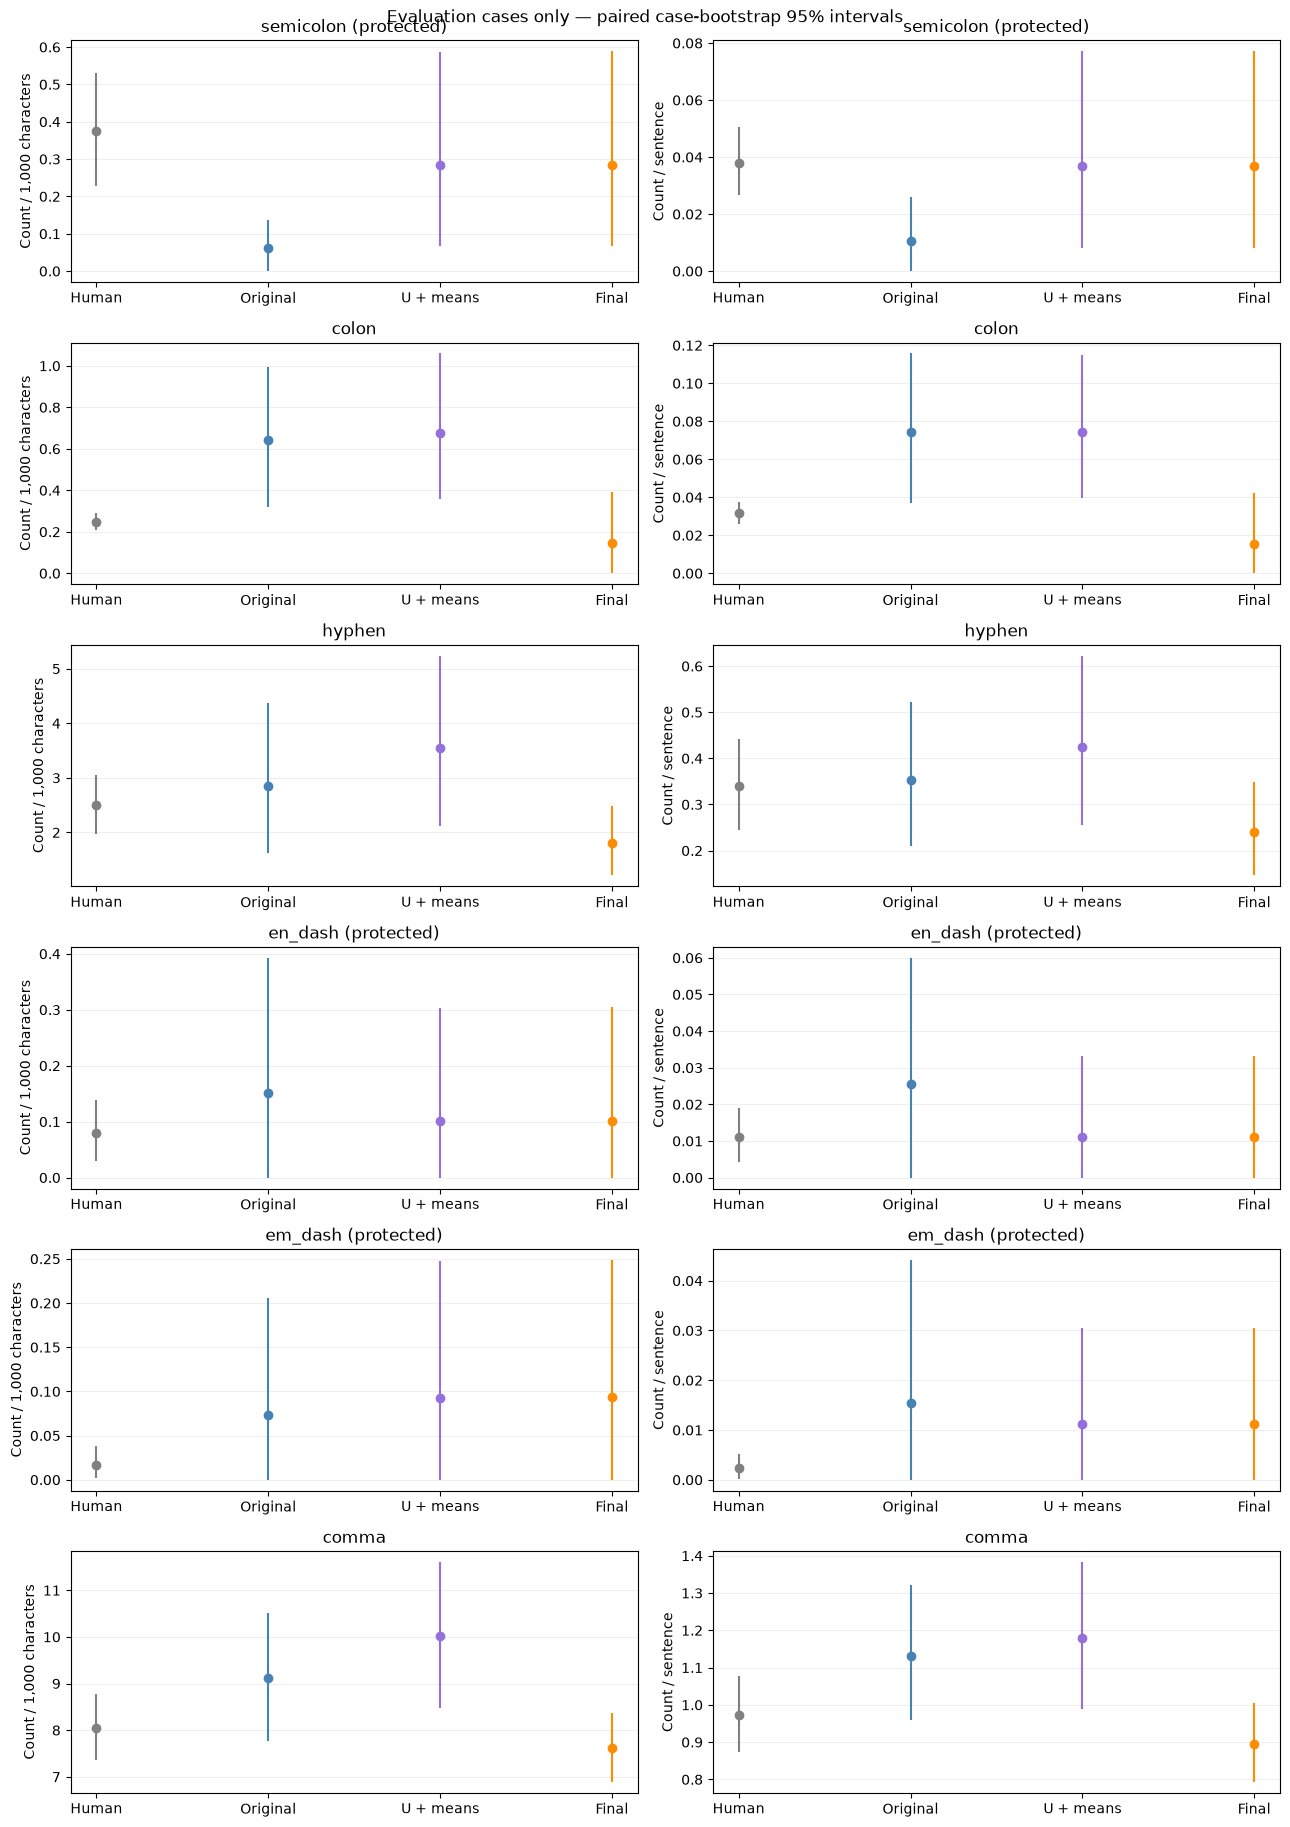

,mark,denominator,comparison,mean_difference,ci_low,ci_high
0,semicolon,relative,Final minus Human,-9.015966e-05,-3.752402e-04,2.435987e-04
1,semicolon,relative,Final minus Original AI,2.231324e-04,8.698923e-06,5.015485e-04
2,semicolon,relative,Final minus Unique + sentence means,9.053990e-07,-4.952839e-08,2.107149e-06
3,semicolon,per_sentence,Final minus Human,-1.233242e-03,-3.188533e-02,3.699124e-02
4,semicolon,per_sentence,Final minus Original AI,2.631898e-02,-5.268031e-03,6.362106e-02
5,semicolon,per_sentence,Final minus Unique + sentence means,0.000000e+00,0.000000e+00,0.000000e+00
6,colon,relative,Final minus Human,-1.014636e-04,-2.646430e-04,1.354400e-04
7,colon,relative,Final minus Original AI,-4.947543e-04,-7.599554e-04,-2.579158e-04
8,colon,relative,Final minus Unique + sentence means,-5.295299e-04,-8.178539e-04,-2.842502e-04
9,colon,per_sentence,Final minus Human,-1.613320e-02,-3.441304e-02,1.056269e-02


,before_gap,final_gap,ci_low,ci_high,selected_in_discovery
share_google_top10000,0.006843,0.006038,0.001193,0.010920,True
pos_1gram_overlap_bin_9,0.006037,0.005976,0.002320,0.009566,True
pos_1gram_overlap_bin_7,0.005343,0.005913,0.003342,0.008617,False
words_per_sentence,0.005777,0.005582,0.004436,0.006757,True
n_sentences,0.005643,0.005380,0.003787,0.007002,True
share_long_words,0.004981,0.005243,0.002660,0.007984,True
pos_3gram_overlap_bin_2,0.004545,0.005089,0.002923,0.007361,False
punct_relative_exclamation,0.004677,0.004967,0.000233,0.011101,False
mcalpine_eflaw,0.004547,0.004802,0.003644,0.006059,True
punct_per_sentence_hyphen,0.004994,0.004741,0.002972,0.006765,True


Saved: ../results/causal/C02r_discovery_gated_punctuation


In [22]:
review=[]; audits=[]; feature_rows=[]; contribution_rows=[]; rate_rows=[]
for p,r in final_results:
    c=p['case']; before=p['text'];after=r['text'];cid=c['case_id']
    review.append(dict(case_id=cid,domain=c['domain'],before=before,after=after,
        periods_preserved=before.count('.')==after.count('.'),sentences_preserved=stats_for(before)['S']==stats_for(after)['S'],
        wps_change=stats_for(after)['wps_mean']-stats_for(before)['wps_mean'],cps_change=stats_for(after)['cps_mean']-stats_for(before)['cps_mean'],
        unique_change=stats_for(after)['share_unique_words']-stats_for(before)['share_unique_words']))
    for m,ds in active.items():
        audits.append(dict(case_id=cid,mark=m,eligible=bool(ds),target=p['targets'].get(m),final_count=after.count(PMARKS[m]),
            loss=mark_loss(after,p,m) if ds else 0.,protected_count_preserved=before.count(PMARKS[m])==after.count(PMARKS[m]) if not ds else None))
    texts={'Original AI':normalize(c['original']),'Unique + sentence means':before,'Final gated':after}
    f=frame_for(list(texts.values()));co=contributions(f[model_features])
    for i,(cond,text) in enumerate(texts.items()):
        feature_rows.append(dict(case_id=cid,condition=cond,**dict(zip(FEATURE_NAMES,f.iloc[i]))))
        contribution_rows.append(dict(case_id=cid,condition=cond,**dict(zip(model_features,co[i]))))
        rr=rates(text)
        for (m,d),v in rr.items():rate_rows.append(dict(case_id=cid,condition=cond,mark=m,denominator=d,value=v))
    contribution_rows.append(dict(case_id=cid,condition='Human',**human_contrib.loc[c['reference_ids']].mean().to_dict()))
    hr=[rates(normalize(text_map[sid])) for sid in c['reference_ids']]
    for m in PMARKS:
        for d in DENOMS:rate_rows.append(dict(case_id=cid,condition='Human',mark=m,denominator=d,value=float(np.mean([v[m,d] for v in hr]))))
review=pd.DataFrame(review);audit=pd.DataFrame(audits);rate_frame=pd.DataFrame(rate_rows)
review.to_csv(OUT/'text_pairs.csv',index=False);audit.to_csv(OUT/'target_outcomes.csv',index=False)
if not (OUT/'manual_review.csv').exists():review.assign(meaning_preserved='',grammar_acceptable='',notes='').to_csv(OUT/'manual_review.csv',index=False)
pd.DataFrame(feature_rows).to_csv(OUT/'evaluation_feature_values.csv',index=False)
cf=pd.DataFrame(contribution_rows).set_index(['case_id','condition']);cf.to_csv(OUT/'evaluation_contributions.csv')
rate_frame.to_csv(OUT/'evaluation_punctuation_rates.csv',index=False)
display(audit.assign(met=audit.loss<=1e-10).groupby('mark').agg(eligible=('eligible','first'),met=('met','sum'),cases=('case_id','size')))
display(review.drop(columns=['before','after']))
conditions=['Human','Original AI','Unique + sentence means','Final gated']
ids=[p['case']['case_id'] for p,r in final_results]
rg=stable_rng('evaluation_ci');idx=rg.integers(len(ids),size=(BOOTSTRAPS,len(ids)))
summary=[];diffs=[]
fig,axes=plt.subplots(len(PMARKS),2,figsize=(13,3.1*len(PMARKS)),squeeze=False)
for row,m in enumerate(PMARKS):
    for col,d in enumerate(DENOMS):
        wide=rate_frame.loc[(rate_frame.mark==m)&(rate_frame.denominator==d)].pivot(index='case_id',columns='condition',values='value').loc[ids,conditions]
        a=wide.to_numpy();b=a[idx].mean(1);mu=a.mean(0);lo,hi=np.quantile(b,[.025,.975],axis=0)
        scale=1000 if d=='relative' else 1
        ax=axes[row,col]
        for j,cond in enumerate(conditions):
            summary.append(dict(mark=m,denominator=d,condition=cond,mean=mu[j],ci_low=lo[j],ci_high=hi[j],n_cases=len(ids)))
            ax.vlines(j,lo[j]*scale,hi[j]*scale,color=['gray','steelblue','mediumpurple','darkorange'][j]);ax.scatter(j,mu[j]*scale,color=['gray','steelblue','mediumpurple','darkorange'][j])
        for j in range(3):
            diff=b[:,3]-b[:,j];dl,dh=np.quantile(diff,[.025,.975])
            diffs.append(dict(mark=m,denominator=d,comparison='Final minus '+conditions[j],mean_difference=mu[3]-mu[j],ci_low=dl,ci_high=dh))
        ax.set_xticks(range(4),['Human','Original','U + means','Final']);ax.set_title(m+(' (protected)' if not active[m] else ''))
        ax.set_ylabel('Count / 1,000 characters' if d=='relative' else 'Count / sentence');ax.grid(axis='y',alpha=.2)
fig.suptitle('Evaluation cases only — paired case-bootstrap 95% intervals');fig.tight_layout();fig.savefig(OUT/'evaluation_punctuation_ci.png',dpi=160);plt.show()
pd.DataFrame(summary).to_csv(OUT/'evaluation_punctuation_ci.csv',index=False)
pd.DataFrame(diffs).to_csv(OUT/'evaluation_paired_differences.csv',index=False);display(pd.DataFrame(diffs))
before_gap=cf.xs('Unique + sentence means',level='condition').loc[ids]-cf.xs('Human',level='condition').loc[ids]
final_gap=cf.xs('Final gated',level='condition').loc[ids]-cf.xs('Human',level='condition').loc[ids]
b=final_gap.to_numpy()[idx].mean(1)
residual=pd.DataFrame({'before_gap':before_gap.mean(),'final_gap':final_gap.mean(),'ci_low':np.quantile(b,.025,axis=0),'ci_high':np.quantile(b,.975,axis=0)})
residual['selected_in_discovery']=residual.index.isin(selected)
residual=residual.sort_values('final_gap',ascending=False);residual.to_csv(OUT/'evaluation_residual_ranking.csv');display(residual.head(30))
import difflib
for row in review.itertuples():
    if row.before==row.after:continue
    display(HTML('<h4>'+html.escape(row.case_id)+'</h4><pre style="white-space:pre-wrap">'+html.escape('\n'.join(difflib.unified_diff(row.before.split(),row.after.split(),fromfile='Before',tofile='After',lineterm='')) )+'</pre>'))
print('Saved:',OUT)


AI score: lower = more human-like to the frozen detector.


,condition,mean_AI_score,median_AI_score,ci_low,ci_high,n_cases
0,Original AI,0.573233,0.553188,0.539691,0.611310,30
1,Unique + sentence means,0.526728,0.526043,0.490922,0.563009,30
2,Final gated,0.481718,0.490573,0.451713,0.514607,30


Paired changes: negative = lower AI score.


,comparison,mean_change,ci_low,ci_high,cases_decreased,cases_increased,cases_unchanged
0,Unique + S/W/C minus Original,-0.046504,-0.075866,-0.019805,20,8,2
1,Punctuation: Final minus Unique + S/W/C,-0.045011,-0.074184,-0.020330,22,5,3
2,Total: Final minus Original,-0.091515,-0.128418,-0.056298,26,4,0


,Original AI,Unique + sentence means,Final gated,punctuation_change,total_change
case_id,,,,,
gate_0008,0.582719,0.570230,0.577319,0.007089,-0.005400
gate_0009,0.547998,0.547998,0.552471,0.004472,0.004472
gate_0011,0.739680,0.740797,0.525489,-0.215309,-0.214191
gate_0012,0.738395,0.748290,0.766843,0.018553,0.028448
gate_0014,0.573550,0.423173,0.405677,-0.017495,-0.167873
gate_0031,0.578694,0.599041,0.443741,-0.155300,-0.134953
gate_0032,0.779500,0.475711,0.463621,-0.012090,-0.315879
gate_0033,0.685783,0.537159,0.508991,-0.028168,-0.176792
gate_0034,0.540213,0.398938,0.380267,-0.018671,-0.159946


Top remaining AI-ward features: mean contribution minus matched human.


,rank,before_punctuation_gap,final_gap,punctuation_change,ci_low,ci_high,fraction_cases_AIward
feature,,,,,,,
share_google_top10000,1,0.006843,0.006038,-0.000805,0.001172,0.011106,0.633333
pos_1gram_overlap_bin_9,2,0.006037,0.005976,-0.000061,0.002356,0.009551,0.733333
pos_1gram_overlap_bin_7,3,0.005343,0.005913,0.000570,0.003474,0.008646,0.800000
words_per_sentence,4,0.005777,0.005582,-0.000195,0.004456,0.006745,0.966667
n_sentences,5,0.005643,0.005380,-0.000262,0.003801,0.007044,0.966667
share_long_words,6,0.004981,0.005243,0.000263,0.002688,0.008071,0.733333
pos_3gram_overlap_bin_2,7,0.004545,0.005089,0.000543,0.003042,0.007258,0.833333
punct_relative_exclamation,8,0.004677,0.004967,0.000290,-0.000033,0.011161,0.500000
mcalpine_eflaw,9,0.004547,0.004802,0.000255,0.003696,0.006044,1.000000


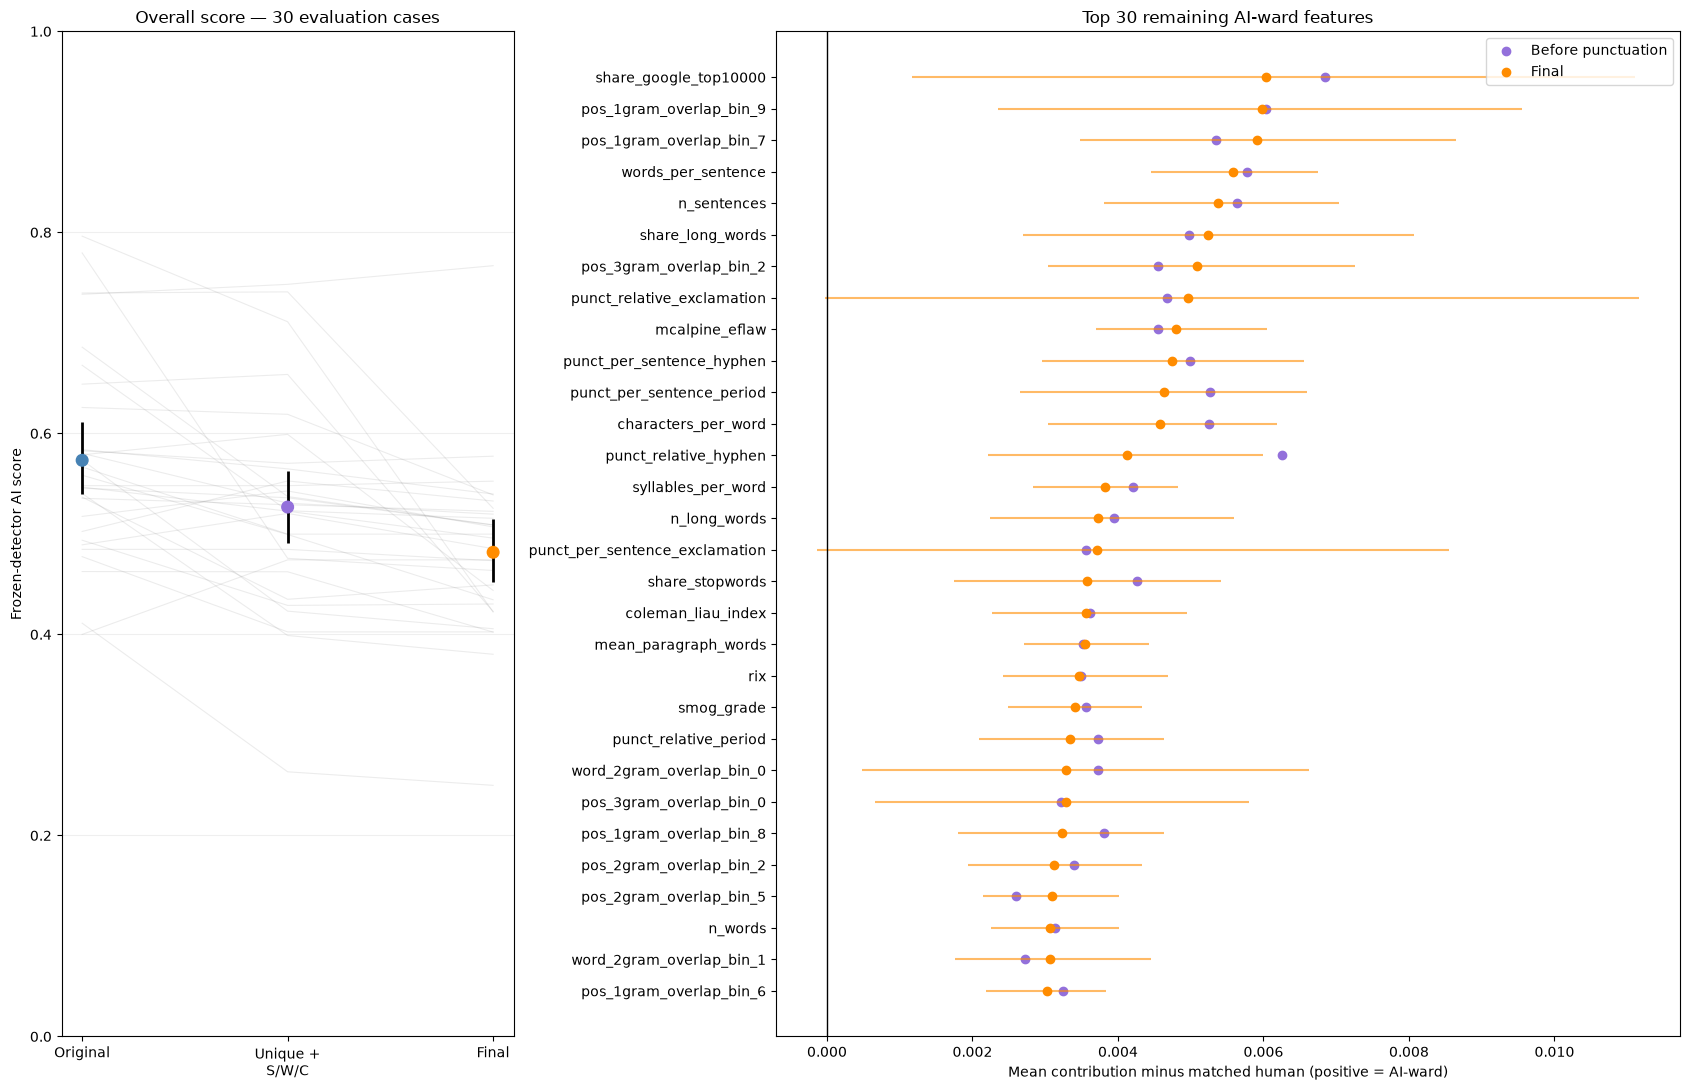

95% paired case-bootstrap CIs; fixed human reference pools. Feature ranking is descriptive and does not update the intervention gate.


In [23]:
# Evaluation cases only; frozen detector, fixed human references.
conditions = ["Original AI", "Unique + sentence means", "Final gated"]
ids = [p["case"]["case_id"] for p, _ in final_results]

fv = pd.read_csv(OUT / "evaluation_feature_values.csv")
fv = fv.set_index(["case_id", "condition"])
contrib = pd.read_csv(OUT / "evaluation_contributions.csv")
contrib = contrib.set_index(["case_id", "condition"])

score_rows = []
for cond in conditions:
    X = fv.xs(cond, level="condition").loc[ids, model_features]
    score_rows.append(pd.Series(
        detector.predict_proba(X)[:, 1], index=ids, name=cond
    ))
scores = pd.concat(score_rows, axis=1)
scores.index.name = "case_id"

rng = np.random.default_rng(SELECTION_SEED + 271)
idx = rng.integers(len(ids), size=(BOOTSTRAPS, len(ids)))
a = scores.to_numpy()
boot = a[idx].mean(axis=1)

score_summary = pd.DataFrame({
    "condition": conditions,
    "mean_AI_score": a.mean(axis=0),
    "median_AI_score": np.median(a, axis=0),
    "ci_low": np.quantile(boot, .025, axis=0),
    "ci_high": np.quantile(boot, .975, axis=0),
    "n_cases": len(ids),
})

comparisons = [
    ("Unique + S/W/C minus Original", 1, 0),
    ("Punctuation: Final minus Unique + S/W/C", 2, 1),
    ("Total: Final minus Original", 2, 0),
]
change_rows = []
for label, after, before in comparisons:
    delta = a[:, after] - a[:, before]
    draws = boot[:, after] - boot[:, before]
    lo, hi = np.quantile(draws, [.025, .975])
    change_rows.append({
        "comparison": label,
        "mean_change": delta.mean(),
        "ci_low": lo,
        "ci_high": hi,
        "cases_decreased": int((delta < -1e-10).sum()),
        "cases_increased": int((delta > 1e-10).sum()),
        "cases_unchanged": int((np.abs(delta) <= 1e-10).sum()),
    })
changes = pd.DataFrame(change_rows)

print("AI score: lower = more human-like to the frozen detector.")
display(score_summary.round(6))
print("Paired changes: negative = lower AI score.")
display(changes.round(6))

per_case = scores.copy()
per_case["punctuation_change"] = (
    scores["Final gated"] - scores["Unique + sentence means"]
)
per_case["total_change"] = scores["Final gated"] - scores["Original AI"]
display(per_case.round(6))

# Remaining contributions: signed gap against each case's matched humans.
human = contrib.xs("Human", level="condition").loc[ids, model_features]
before = contrib.xs(
    "Unique + sentence means", level="condition"
).loc[ids, model_features]
final = contrib.xs("Final gated", level="condition").loc[ids, model_features]

before_gap = before - human
final_gap = final - human
gap_boot = final_gap.to_numpy()[idx].mean(axis=1)

remaining = pd.DataFrame({
    "before_punctuation_gap": before_gap.mean(),
    "final_gap": final_gap.mean(),
    "punctuation_change": (final - before).mean(),
    "ci_low": np.quantile(gap_boot, .025, axis=0),
    "ci_high": np.quantile(gap_boot, .975, axis=0),
    "fraction_cases_AIward": (final_gap > 0).mean(),
})
remaining.index.name = "feature"
remaining = remaining.sort_values("final_gap", ascending=False)
remaining.insert(0, "rank", np.arange(1, len(remaining) + 1))

# Check that feature changes reconstruct the detector-score changes.
np.testing.assert_allclose(
    (final - before).sum(axis=1).to_numpy(),
    per_case["punctuation_change"].to_numpy(),
    atol=1e-8, rtol=0,
)

top = remaining.loc[remaining.final_gap > 0].head(30)
print("Top remaining AI-ward features: mean contribution minus matched human.")
display(top.round(6))

fig, axes = plt.subplots(
    1, 2, figsize=(17, 11), gridspec_kw={"width_ratios": [1, 2]}
)

# Overall scores, with individual paired trajectories.
for row in a:
    axes[0].plot(range(3), row, color="gray", alpha=.15, lw=.8)
lo, hi = np.quantile(boot, [.025, .975], axis=0)
axes[0].vlines(range(3), lo, hi, color="black", lw=2)
axes[0].scatter(
    range(3), a.mean(axis=0),
    c=["steelblue", "mediumpurple", "darkorange"], s=70, zorder=3,
)
axes[0].set_xticks(range(3), ["Original", "Unique +\nS/W/C", "Final"])
axes[0].set(
    ylabel="Frozen-detector AI score",
    ylim=(0, 1),
    title=f"Overall score — {len(ids)} evaluation cases",
)
axes[0].grid(axis="y", alpha=.2)

plot = top.iloc[::-1]
y = np.arange(len(plot))
axes[1].hlines(y, plot.ci_low, plot.ci_high, color="darkorange", alpha=.6)
axes[1].scatter(
    plot.before_punctuation_gap, y, color="mediumpurple",
    label="Before punctuation",
)
axes[1].scatter(plot.final_gap, y, color="darkorange", label="Final")
axes[1].axvline(0, color="black", lw=1)
axes[1].set_yticks(y, plot.index)
axes[1].set(
    xlabel="Mean contribution minus matched human (positive = AI-ward)",
    title="Top 30 remaining AI-ward features",
)
axes[1].legend()
fig.tight_layout()
plt.show()

score_summary.to_csv(OUT / "overall_AI_score_summary.csv", index=False)
changes.to_csv(OUT / "overall_AI_score_changes.csv", index=False)
per_case.to_csv(OUT / "overall_AI_scores_per_case.csv")
remaining.to_csv(OUT / "remaining_AIward_features.csv")
fig.savefig(OUT / "overall_AI_scores_and_remaining_features.png",
            dpi=180, bbox_inches="tight")

print(
    "95% paired case-bootstrap CIs; fixed human reference pools. "
    "Feature ranking is descriptive and does not update the intervention gate."
)

,evaluation_AI_cases,heldout_human_documents,human_genre_weight
abstracts,7,23,0.233333
books,2,18,0.066667
news,5,25,0.166667
recipes,6,21,0.200000
reddit,4,16,0.133333
wiki,6,19,0.200000


Full empirical ROC AUC; 0.5 is the chance reference.


,condition,ROC_AUC,n_AI,n_human
0,Original AI,0.8472,30,122
1,Unique + sentence means,0.7533,30,122
2,Final gated,0.6485,30,122


TPR at human FPR budgets (percent):


,Requested FPR %,Achieved FPR %,Original AI TPR %,Unique + sentence means TPR %,Final gated TPR %
0,1.0,0.95,13.33,10.00,3.33
1,5.0,4.48,23.33,13.33,3.33
2,10.0,9.45,50.00,30.00,10.00
3,20.0,19.87,70.00,56.67,26.67
4,30.0,28.99,80.00,66.67,50.00
5,40.0,39.75,93.33,80.00,63.33
6,50.0,49.17,93.33,80.00,70.00
7,60.0,59.91,93.33,90.00,83.33
8,70.0,69.99,100.00,96.67,93.33
9,80.0,79.64,100.00,96.67,96.67


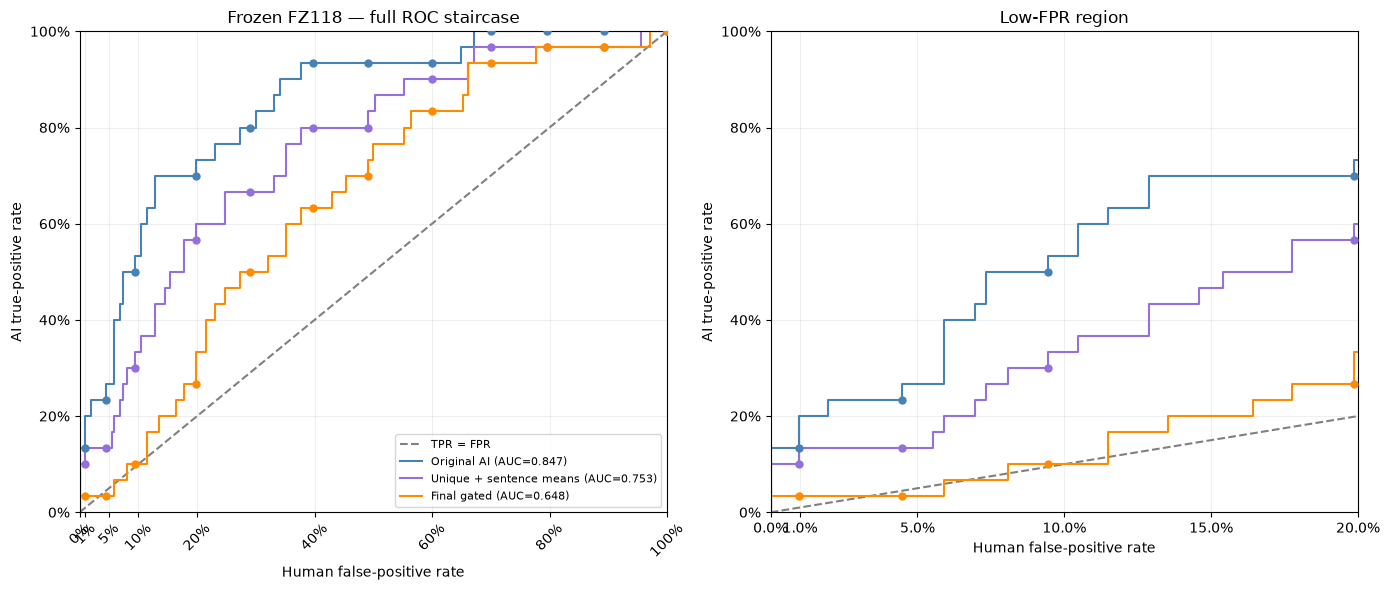

Empirical evaluation: 30 AI cases and 122 held-out humans. With 30 AI cases, TPR changes in steps of 3.33 percentage points. Finite human support and ties can make achieved FPR lower than requested. These thresholds are descriptive test-set operating points, not independently calibrated deployment thresholds.


In [24]:
# ROC staircase and TPR at requested human FPR budgets.
# Run after the overall-score cell. No generation or editing is repeated.

conditions = ["Original AI", "Unique + sentence means", "Final gated"]
eval_cases = [p["case"] for p, _ in final_results]
case_ids = [c["case_id"] for c in eval_cases]

# Load the saved AI scores.
score_path = OUT / "overall_AI_scores_per_case.csv"
roc_scores = pd.read_csv(score_path).set_index("case_id")
ai = roc_scores.loc[case_ids, conditions].to_numpy(float)

# Individual held-out humans; never use training humans for this ROC.
genre_mix = pd.Series(
    [c["domain"] for c in eval_cases]
).value_counts(normalize=True)

human_test = features.loc[
    (features.dataset == "raid")
    & (features.split == EVAL_SPLIT)
    & (features.label == 0)
    & features.domain.isin(genre_mix.index)
].copy()

assert human_test.source_id.is_unique
assert set(genre_mix.index) <= set(human_test.domain), (
    "Some evaluation genres have no held-out humans."
)
assert len(human_test) > 0

# Cached features use the same frozen feature contract.
h = detector.predict_proba(human_test[model_features])[:, 1]
genre_counts = human_test.domain.value_counts()
hw = np.array([
    genre_mix[g] / genre_counts[g] for g in human_test.domain
], dtype=float)
hw /= hw.sum()

assert np.isfinite(h).all() and np.isfinite(ai).all()

display(pd.DataFrame({
    "evaluation_AI_cases": pd.Series(
        [c["domain"] for c in eval_cases]
    ).value_counts(),
    "heldout_human_documents": genre_counts,
    "human_genre_weight": genre_mix,
}).fillna(0))

# Full empirical ROC: include every observed AI and human score.
# Prediction rule is score >= threshold; tied scores move together.
thresholds = np.r_[
    np.inf,
    np.sort(np.unique(np.r_[h, ai.ravel()]))[::-1],
    -np.inf,
]
fpr = np.array([hw[h >= t].sum() for t in thresholds])
tpr = np.array([
    (ai >= t).mean(axis=0) for t in thresholds
])

auc_rows = []
for j, cond in enumerate(conditions):
    auc_value = np.sum(
        np.diff(fpr) * (tpr[1:, j] + tpr[:-1, j]) / 2
    )
    auc_rows.append({
        "condition": cond,
        "ROC_AUC": auc_value,
        "n_AI": len(ai),
        "n_human": len(h),
    })
auc_table = pd.DataFrame(auc_rows)

# Operating thresholds depend ONLY on held-out human scores.
# Choose the most permissive threshold whose empirical FPR
# does not exceed the requested budget. No randomized tie breaking.
budgets = np.array([.01, .05, .10, .20, .30, .40,
                    .50, .60, .70, .80, .90, 1.00])

human_thresholds = np.r_[
    np.inf, np.sort(np.unique(h))[::-1], -np.inf
]
human_fprs = np.array([
    hw[h >= t].sum() for t in human_thresholds
])

rows = []
for budget in budgets:
    k = np.flatnonzero(human_fprs <= budget + 1e-12)[-1]
    threshold = human_thresholds[k]
    detected = (ai >= threshold).mean(axis=0)
    rows.append({
        "requested_FPR": budget,
        "achieved_FPR": human_fprs[k],
        "threshold": threshold,
        **dict(zip(conditions, detected)),
    })
operating = pd.DataFrame(rows)

print("Full empirical ROC AUC; 0.5 is the chance reference.")
display(auc_table.round(4))

print("TPR at human FPR budgets (percent):")
display(
    operating.drop(columns="threshold")
    .mul(100).round(2)
    .rename(columns={
        "requested_FPR": "Requested FPR %",
        "achieved_FPR": "Achieved FPR %",
        **{c: c + " TPR %" for c in conditions},
    })
)

colors = ["steelblue", "mediumpurple", "darkorange"]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax in axes:
    ax.plot([0, 1], [0, 1], "--", color="gray", label="TPR = FPR")
    for j, (cond, color) in enumerate(zip(conditions, colors)):
        ax.step(
            fpr, tpr[:, j], where="post", color=color,
            label=f"{cond} (AUC={auc_table.iloc[j].ROC_AUC:.3f})",
        )
        ax.scatter(
            operating.achieved_FPR, operating[cond],
            color=color, s=25, zorder=3,
        )
    ax.set_xlabel("Human false-positive rate")
    ax.set_ylabel("AI true-positive rate")
    ax.grid(alpha=.2)

axes[0].set(
    xlim=(0, 1), ylim=(0, 1),
    title="Frozen FZ118 — full ROC staircase",
)
axes[0].set_xticks([0, .01, .05, .10, .20, .40, .60, .80, 1])
axes[0].tick_params(axis="x", labelrotation=45)
axes[0].legend(fontsize=8)

axes[1].set(
    xlim=(0, .20), ylim=(0, 1),
    title="Low-FPR region",
)
axes[1].set_xticks([0, .01, .05, .10, .15, .20])

from matplotlib.ticker import PercentFormatter
for ax in axes:
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))

fig.tight_layout()
plt.show()

operating.to_csv(OUT / "TPR_at_FPR_budgets.csv", index=False)
auc_table.to_csv(OUT / "ROC_AUC_summary.csv", index=False)
pd.DataFrame({
    "threshold": thresholds,
    "FPR": fpr,
    **{c: tpr[:, j] for j, c in enumerate(conditions)},
}).to_csv(OUT / "ROC_staircase.csv", index=False)
fig.savefig(OUT / "ROC_staircase.png", dpi=180, bbox_inches="tight")

print(
    f"Empirical evaluation: {len(ai)} AI cases and {len(h)} held-out humans. "
    "With 30 AI cases, TPR changes in steps of 3.33 percentage points. "
    "Finite human support and ties can make achieved FPR lower than requested. "
    "These thresholds are descriptive test-set operating points, "
    "not independently calibrated deployment thresholds."
)

In [15]:
# gate_0004 only: ordinary, controlled, and ordinary continuation before word 49.
import copy
import json
import time
from pathlib import Path
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

CASE_ID = "gate_0004"
DIAG = OUT / "diagnostics" / "gate_0004_replay_v1"
DIAG.mkdir(parents=True, exist_ok=True)

case = next(c for c in cases if c["case_id"] == CASE_ID)
saved = json.loads(
    (OUT / CASE_ID / "controlled" / "state.json").read_text()
)
assert saved["contract_hash"] == CONTRACT_HASH
failed = saved["state"]

# Require the search guard to be installed before controlled replay.
assert "_search_word_before_budget" in globals(), (
    "Run the existing search-budget definition cell first, "
    "but do not rerun the cohort-generation cell."
)
assert SEARCH_BUDGET["max_expanded"] == 500
assert SEARCH_BUDGET["max_frontier"] == 5000

# Restore the original generation model if later cells unloaded/replaced it.
generation_revision = contract.get("resolved_revision") or MODEL_REVISION
tokenizer_revision = contract.get("tokenizer_revision") or generation_revision

loaded_model = globals().get("model")
if (
    loaded_model is None
    or getattr(loaded_model.config, "_name_or_path", "") != MODEL_ID
):
    if loaded_model is not None:
        del loaded_model
    globals().pop("model", None)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID, revision=generation_revision, dtype=DTYPE
    ).to(DEVICE).eval()

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID, revision=tokenizer_revision
)

import inspect
EOS_IDS = model.generation_config.eos_token_id
EOS_IDS = set(EOS_IDS if isinstance(EOS_IDS, (list, tuple)) else [EOS_IDS])
EOS_IDS.discard(None)
if tokenizer.eos_token_id is not None:
    EOS_IDS.add(tokenizer.eos_token_id)
FORBIDDEN_SPECIAL = set(tokenizer.all_special_ids) - EOS_IDS
CONTEXT_SIZE = int(model.config.max_position_embeddings)
KEEP_LAST = "logits_to_keep" in inspect.signature(model.forward).parameters

# Verify that the restored tokenizer reproduces the frozen prompt.
prompt_ids = normalized_prompt_ids(tokenizer.apply_chat_template(
    messages_for(case),
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors=None,
))
assert prompt_ids == case["prompt_ids"], "Frozen prompt tokenization changed."
backend = LocalBackend(prompt_ids)

# Reconstruct the committed prefix through word 48 from the saved token path.
spans = list(backend.word_spans(failed["committed_text"]))
assert len(spans) >= 49
prefix = failed["committed_text"][:spans[47][2]]
prefix_words = [w.lower() for w, _, _ in backend.word_spans(prefix)]
assert prefix_words == failed["words"][:48]

# Keep only the shortest original token prefix covering those 48 words.
# Fail explicitly if a token also contains letters from the following word.
anchor_n = None
for n in range(1, len(failed["ids"]) + 1):
    decoded = backend.decode(failed["ids"][:n])
    if "\ufffd" in decoded:
        continue
    if decoded.startswith(prefix):
        assert not any(ch.isalpha() for ch in decoded[len(prefix):]), (
            "A token straddles word 49; exact pre-edit replay needs "
            "a token-boundary-specific reconstruction."
        )
        anchor_n = n
        break
assert anchor_n is not None

continuation = initial_state("baseline")
continuation.update(
    ids=failed["ids"][:anchor_n],
    probabilities=failed["probabilities"][:anchor_n],
    committed_text=prefix,
    words=prefix_words,
)

seeds = {
    "ordinary_from_prompt": initial_state("baseline"),
    "controlled_from_prompt": initial_state("controlled"),
    "ordinary_after_word48": continuation,
}

# Same current stopping/search policies for all three diagnostic conditions.
# This is a guarded replay, not an exact reproduction of the old unguarded run.
diag_contract = {
    "parent_contract_hash": CONTRACT_HASH,
    "case_id": CASE_ID,
    "generation_revision": generation_revision,
    "search_budget": SEARCH_BUDGET,
    "runaway_policy": RUNAWAY_POLICY,
    "prefix_words": 48,
    "prefix_ids": continuation["ids"],
    "conditions": list(seeds),
}
diag_hash = digest(diag_contract)
contract_path = DIAG / "contract.json"
if contract_path.exists():
    assert json.loads(contract_path.read_text()) == diag_contract
else:
    write_json(contract_path, diag_contract)

rows = []

for name, seed in seeds.items():
    folder = DIAG / name
    folder.mkdir(exist_ok=True)
    state_path = folder / "state.json"

    if state_path.exists():
        payload = json.loads(state_path.read_text())
        assert payload["diagnostic_hash"] == diag_hash
        state = payload["state"]
    else:
        state = copy.deepcopy(seed)

    terminal = (
        state["status"] == "completed_eos"
        or state["status"].startswith("failed_")
    )
    reused = terminal
    last_report = [0.0]

    def save(s):
        write_json(state_path, {
            "diagnostic_hash": diag_hash,
            "state": s,
        })

    def checkpoint(s):
        save(s)
        reason = runaway_reason(s, case)
        if reason is not None:
            s["diagnostic_stop_reason"] = reason
            save(s)
            raise RunawayGeneration(str(reason))

    def report(s):
        now = time.monotonic()
        if now - last_report[0] >= 10:
            print(
                f"{name}: words={len(s['words'])}, "
                f"mode={s['mode']}, edits={s['replacements']}, "
                f"fallbacks={s['fallbacks']}",
                flush=True,
            )
            last_report[0] = now

    if not terminal:
        print(f"\nRunning {name}", flush=True)
        with (folder / "search_audit.jsonl").open("a", buffering=1) as audit:
            def search_log(event):
                audit.write(json.dumps({
                    "word_index": len(state["words"]) + 1,
                    **event,
                }, ensure_ascii=False) + "\n")
                report(state)

            try:
                run_feedback(
                    backend, state, case["curve"], case["warmup_words"],
                    THETA_SCHEDULES, checkpoint, search_log, report,
                )
            except RunawayGeneration:
                state["finished"] = False
                state["status"] = "failed_runaway"
                save(state)
            except KeyboardInterrupt:
                save(state)
                print(f"Checkpoint saved for {name}; rerun this cell to resume.")
                raise
            except Exception:
                save(state)
                raise

    (folder / "text.txt").write_text(state["committed_text"])
    pd.DataFrame(state["trajectory"]).to_csv(
        folder / "word_trajectory.csv", index=False
    )

    rows.append({
        "condition": name,
        "status": state["status"],
        "words": len(state["words"]),
        "unique_words": len(set(state["words"])),
        "replacements": state["replacements"],
        "fallbacks": state["fallbacks"],
        "reused": reused,
        "stop_reason": state.get("diagnostic_stop_reason"),
    })
    pd.DataFrame(rows).to_csv(DIAG / "outcomes.csv", index=False)

    print(f"\n{name} — {state['status']}")
    print(state["committed_text"][:1800])
    if len(state["committed_text"]) > 1800:
        print("\n... LAST 600 CHARACTERS ...\n")
        print(state["committed_text"][-600:])

display(pd.DataFrame(rows))
print("Saved:", DIAG)


ordinary_from_prompt — completed_eos
> 8-1/2 cups water, divided
> 4 small carrots, chopped
> 3 stalks celery, diced
> 4 cloves garlic, minced
> 2 leeks (white part only), cut into pieces
> 6 (6 oz.) packages fresh baby spinach leaves
> One 4 lb turkey, cooked and diced or shredded
> 8 tomatos (or equivalent amount frozen tomatoes)
> 2 tsp dried rosemary
> 2 bay leaves
> Salt & Pepper to taste
> Corn meal noodles: combine in food processor mix 1 cup cornmeal, 1 teaspoon salt, and 4 cups hot tap water; pulse mixture until dough comes together then set aside for 5 minutes. Dust countertop with flour dusted with potato starch or powder sugar. Roll out cornmeal dough as if rolling out pie crust. Cut in strips either by hand or scissors about an inch thick. Bring each strip up at one end like you were making lasagna. Cover pan lightly. Set apart while working on vegetable soup and cooking your broth/stock. Cooking broth: In a large stockpot melt coconut oil over medium heat. Saute garlic t

,condition,status,words,unique_words,replacements,fallbacks,reused,stop_reason
0,ordinary_from_prompt,completed_eos,225,175,0,0,True,None
1,controlled_from_prompt,failed_manual_stop,332,115,67,102,True,"{'reason': 'manual_stop_after_length_overrun',..."
2,ordinary_after_word48,completed_eos,225,175,0,0,False,None


Saved: ../results/causal/C02r_discovery_gated_punctuation/diagnostics/gate_0004_replay_v1


In [14]:
path = DIAG / "controlled_from_prompt" / "state.json"
payload = json.loads(path.read_text())
s = payload["state"]

if s["status"] != "completed_eos":
    s["finished"] = False
    s["status"] = "failed_manual_stop"
    s["diagnostic_stop_reason"] = {
        "reason": "manual_stop_after_length_overrun",
        "words": len(s["words"]),
    }
    write_json(path, payload)
    path.with_name("text.txt").write_text(s["committed_text"])

print(s["status"], len(s["words"]))
print(s["committed_text"][-1500:])

failed_manual_stop 332
per(s)
> 1 kilogram (about 2.2 lbs) corn meal noodles
> 1 cup(s) all-purpose flour
> 1/2 cup(s) potato starch
> 1/2 cup(s) granulated sugar
> 1/2 cup(s) cornmeal
> 1/2 cup(s) melted coconut oil
> 4 cloves(s) garlic
> 2 leeks(s) (whites only)
> 6 (6 oz.) bags(s) of fresh baby spinach
> 4 kilograms (around 8.8 lbs) beef
> 8 medium toms
> 2 teaspoons(s) dried thyme
> 2 bay(s) leaf(s)
> Salt(s)
> Pepper(s)
> 1 kilogram (about 2.2 lbs) corn meal noodles
> 1 cup(s) all-purpose flour
> 1/2 cup(s) potato starch
> 1/2 cup(s) granulated sugar
> 1/2 cup(s) cornmeal
> 1/2 cup(s) melted coconut oil
> 4 cloves(s) garlic
> 2 leeks(s) (whites only)
> 6 (6 oz.) bags(s) of fresh baby spinach
> 4 kilograms (around 8.8 lbs) pork
> 8 tomatillos
> 2 teaspoons(s) dried thyme
> 2 bay(s) leaf(s)
> Salt(s)
> Pepper(s)
> 1 kilogram (about 2.2 lbs) corn meal noodles
> 1 cup(s) all-purpose flour
> 1/2 cup(s) potato starch
> 1/2 cup(s) granulated sugar
> 1/2 cup(s) cornmeal
> 1/2 cup(s) melte

In [17]:
# gate_0004 only — relative-likelihood guard, diagnostic threshold = 0.20.
import math
import copy
import json
import time
import pandas as pd

RATIO_FLOOR = 0.10
guard_dir = DIAG / "controlled_relative_likelihood_010"
guard_dir.mkdir(parents=True, exist_ok=True)

assert case["case_id"] == "gate_0004"
assert "_search_word_before_budget" in globals()
assert model.config._name_or_path == MODEL_ID

# Capture the existing budgeted search; restore it after this experiment.
original_search = search_word

def word_path_logp(result, anchor):
    """Conditional token-path probability through the completed word.

    Excludes lookahead tokens after the token covering the word's final
    character. Includes any punctuation emitted along the candidate path.
    Uses joint log probability, not average log probability per token.
    """
    end = result["view"]["end"]
    target = result["view"]["text"][:end]

    for n in range(anchor + 1, len(result["ids"]) + 1):
        decoded = backend.decode(result["ids"][:n])
        if "\ufffd" not in decoded and decoded.startswith(target):
            probs = result["probabilities"][anchor:n]
            assert probs and all(0 < p <= 1 for p in probs)
            return sum(math.log(p) for p in probs)

    raise RuntimeError("Cannot identify the completed-word token boundary.")

def guarded_search(
    backend, baseline, fixed_prefix, seen, desired, theta,
    on_search=lambda event: None,
):
    candidate = original_search(
        backend, baseline, fixed_prefix, seen, desired, theta, on_search
    )
    if candidate["exhausted"]:
        return candidate

    anchor = candidate["anchor"]
    baseline_logp = word_path_logp(baseline, anchor)
    candidate_logp = word_path_logp(candidate, anchor)
    log_ratio = candidate_logp - baseline_logp
    accepted = log_ratio >= math.log(RATIO_FLOOR)

    on_search({
        "event": "relative_likelihood_guard",
        "ordinary_word": baseline["view"]["word"],
        "candidate_word": candidate["view"]["word"],
        "ordinary_logp": baseline_logp,
        "candidate_logp": candidate_logp,
        "log_ratio": log_ratio,
        "ratio_floor": RATIO_FLOOR,
        "accepted": accepted,
    })

    if accepted:
        return candidate

    # Operational fallback, explicitly not exhaustive search.
    return {
        "exhausted": True,
        "search_exhausted": False,
        "fallback_reason": "relative_likelihood_rejected",
        "anchor": anchor,
        "expanded": candidate.get("expanded", 0),
        "completed_candidates": candidate.get("completed_candidates", 0),
        "distinct_candidates": candidate.get("distinct_candidates", 0),
    }

guard_contract = {
    "parent_diagnostic_hash": diag_hash,
    "case_id": case["case_id"],
    "ratio_floor": RATIO_FLOOR,
    "scoring": "joint_token_path_through_word_end_v1",
    "rejection_policy": "ordinary_fallback_no_additional_search",
    "search_budget": SEARCH_BUDGET,
    "runaway_policy": RUNAWAY_POLICY,
}
guard_hash = digest(guard_contract)
contract_path = guard_dir / "contract.json"
if contract_path.exists():
    assert json.loads(contract_path.read_text()) == guard_contract
else:
    write_json(contract_path, guard_contract)

state_path = guard_dir / "state.json"
if state_path.exists():
    payload = json.loads(state_path.read_text())
    assert payload["guard_hash"] == guard_hash
    guarded_state = payload["state"]
else:
    guarded_state = initial_state("controlled")

def save_guarded(s):
    write_json(state_path, {"guard_hash": guard_hash, "state": s})

def checkpoint_guarded(s):
    save_guarded(s)
    reason = runaway_reason(s, case)
    if reason is not None:
        s["diagnostic_stop_reason"] = reason
        save_guarded(s)
        raise RunawayGeneration(str(reason))

last_report = [0.0]
def report_guarded(s):
    now = time.monotonic()
    if now - last_report[0] >= 10:
        print(
            f"guarded: words={len(s['words'])}, mode={s['mode']}, "
            f"edits={s['replacements']}, fallbacks={s['fallbacks']}",
            flush=True,
        )
        last_report[0] = now

terminal = (
    guarded_state["status"] == "completed_eos"
    or guarded_state["status"].startswith("failed_")
)

if not terminal:
    search_word = guarded_search
    try:
        with (guard_dir / "search_audit.jsonl").open(
            "a", buffering=1
        ) as audit:
            def log_guarded(event):
                audit.write(json.dumps({
                    "word_index": len(guarded_state["words"]) + 1,
                    **event,
                }) + "\n")
                report_guarded(guarded_state)

            try:
                run_feedback(
                    backend, guarded_state, case["curve"],
                    case["warmup_words"], THETA_SCHEDULES,
                    checkpoint_guarded, log_guarded, report_guarded,
                )
            except RunawayGeneration:
                guarded_state["finished"] = False
                guarded_state["status"] = "failed_runaway"
                save_guarded(guarded_state)
    finally:
        search_word = original_search

(guard_dir / "text.txt").write_text(guarded_state["committed_text"])
pd.DataFrame(guarded_state["trajectory"]).to_csv(
    guard_dir / "word_trajectory.csv", index=False
)

# Compare with saved runs; no regeneration of those conditions.
comparison = []
for name, folder in [
    ("ordinary", DIAG / "ordinary_from_prompt"),
    ("original_controlled", DIAG / "controlled_from_prompt"),
    ("relative_likelihood_020", guard_dir),
]:
    s = json.loads((folder / "state.json").read_text())["state"]
    W = len(s["words"])
    comparison.append({
        "condition": name,
        "status": s["status"],
        "words": W,
        "unique_words": len(set(s["words"])),
        "unique_share": len(set(s["words"])) / W if W else None,
        "replacements": s["replacements"],
        "fallbacks": s["fallbacks"],
    })

comparison = pd.DataFrame(comparison)
comparison.to_csv(guard_dir / "comparison.csv", index=False)
display(comparison)
print(guarded_state["committed_text"])
print("\nSaved:", guard_dir)

guarded: words=1, mode=normal, edits=0, fallbacks=0
guarded: words=44, mode=decrease, edits=0, fallbacks=8
guarded: words=56, mode=decrease, edits=0, fallbacks=20
guarded: words=77, mode=decrease, edits=0, fallbacks=37
guarded: words=79, mode=decrease, edits=0, fallbacks=39
guarded: words=79, mode=decrease, edits=0, fallbacks=39
guarded: words=79, mode=decrease, edits=0, fallbacks=39
guarded: words=79, mode=decrease, edits=0, fallbacks=39
guarded: words=79, mode=decrease, edits=0, fallbacks=39
guarded: words=79, mode=decrease, edits=0, fallbacks=39
guarded: words=79, mode=decrease, edits=0, fallbacks=39
guarded: words=79, mode=decrease, edits=0, fallbacks=39
guarded: words=82, mode=decrease, edits=2, fallbacks=40
guarded: words=100, mode=decrease, edits=3, fallbacks=53
guarded: words=101, mode=decrease, edits=3, fallbacks=54
guarded: words=112, mode=decrease, edits=3, fallbacks=64
guarded: words=129, mode=decrease, edits=3, fallbacks=79
guarded: words=129, mode=decrease, edits=3, fallb

,condition,status,words,unique_words,unique_share,replacements,fallbacks
0,ordinary,completed_eos,225,175,0.777778,0,0
1,original_controlled,failed_manual_stop,332,115,0.346386,67,102
2,relative_likelihood_020,completed_eos,224,168,0.750000,11,135


> 8-1/2 cups water, divided
> 4 small carrots, chopped
> 3 stalks celery, diced
> 4 cloves garlic, minced
> 2 leeks (white part only), cut into pieces
> 6 (6 oz.) packages fresh baby spinach leaves
> One 4 lb turkey, cooked and diced or shredded
> 8 tomatos (or equivalent amount frozen tomatoes)
> 2 tsp dried rosemary
> 2 bay leaves
> Salt & Pepper to taste
> Corn meal noodles: combine in food processor mix 1 cup cornmeal, 1 teaspoon salt, and 4 cups hot tap water; pulse mixture until dough comes together then set aside for 5 minutes. Dust countertop with flour and corn starch. Roll out dough as if rolling out pie crust. Cut in strips either by hand or scissors about an inch thick. Bring each strip up at one end like you were making lasagna. Cover pan lightly. Set apart while working on vegetable soup and cooking your broth/stock. Cooking broth: In a large stock pot melt coconut oil over medium heat. Saute garlic until light golden, being careful not to burn it. Add remaining vegetable

In [18]:
print(json.loads((guard_dir / "contract.json").read_text())["ratio_floor"])

0.1


In [19]:
import json
import pandas as pd

cfg = json.loads((guard_dir / "contract.json").read_text())
s = json.loads((guard_dir / "state.json").read_text())["state"]
trajectory = pd.DataFrame(s["trajectory"])

print("Actual ratio floor:", cfg["ratio_floor"])

# Audit can include interrupted/resumed attempts. Match accepted events
# to the committed trajectory by position and both word strings.
events = [
    json.loads(line)
    for line in (guard_dir / "search_audit.jsonl").read_text().splitlines()
    if line.strip()
]
accepted_events = {}
for e in events:
    if e.get("event") == "relative_likelihood_guard" and e.get("accepted"):
        key = (e["word_index"], e["ordinary_word"], e["candidate_word"])
        accepted_events[key] = e

spans = list(backend.word_spans(s["committed_text"]))
rows = []

for r in trajectory.loc[trajectory.action.eq("backtracked")].to_dict("records"):
    i = int(r["word_index"])
    e = accepted_events.get((i, r["original_word"], r["word"]), {})
    start, end = spans[i - 1][1:]
    text = s["committed_text"]

    rows.append({
        "word_index": i,
        "mode": r["mode_before"],
        "ordinary_word": r["original_word"],
        "chosen_word": r["word"],
        "likelihood_ratio": (
            math.exp(e["log_ratio"]) if "log_ratio" in e else None
        ),
        "unique_share_before": r["k_before"],
        "unique_share_after": r["k_after"],
        "final_context": (
            text[max(0, start - 70):start]
            + "[" + text[start:end] + "]"
            + text[end:end + 70]
        ).replace("\n", " "),
    })

edits = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 180, "display.max_rows", None):
    display(edits)

print(
    "ordinary_word is the greedy alternative at that step's controlled prefix; "
    "it is not necessarily the corresponding word in the ordinary full run."
)

Actual ratio floor: 0.1


,word_index,mode,ordinary_word,chosen_word,likelihood_ratio,unique_share_before,unique_share_after,final_context
0,81,decrease,dusted,and,0.105528,0.912500,0.901235,mes together then set aside for 5 minutes. Dust countertop with flour [and] corn starch. Roll out dough as if rolling out pie crust. Cut in strip
1,82,decrease,potato,corn,0.416862,0.901235,0.890244,together then set aside for 5 minutes. Dust countertop with flour and [corn] starch. Roll out dough as if rolling out pie crust. Cut in strips eit
2,94,decrease,strips,in,0.535261,0.870968,0.861702,lour and corn starch. Roll out dough as if rolling out pie crust. Cut [in] strips either by hand or scissors about an inch thick. Bring each str
3,137,decrease,stockpot,stock,1.044292,0.852941,0.846715,egetable soup and cooking your broth/stock. Cooking broth: In a large [stock] pot melt coconut oil over medium heat. Saute garlic until light golde
4,147,decrease,til,until,0.606531,0.849315,0.843537,"In a large stock pot melt coconut oil over medium heat. Saute garlic [until] light golden, being careful not to burn it. Add remaining vegetables"
5,169,decrease,till,until,0.367879,0.827381,0.822485,"tables including herbs, bring to boil, reduce heat, cover, and simmer [until] tender, about 20-30 minutes. Strain through a colander, discard solid"
6,175,decrease,colander,a,0.417031,0.816092,0.811429,", cover, and simmer until tender, about 20-30 minutes. Strain through [a] colander, discard solids, and use juice for soup if desired. Add more"
7,179,decrease,use,and,0.472367,0.814607,0.810056,"nder, about 20-30 minutes. Strain through a colander, discard solids, [and] use juice for soup if desired. Add more filtered water, organic chick"
8,183,decrease,base,soup,0.119433,0.807692,0.803279,"minutes. Strain through a colander, discard solids, and use juice for [soup] if desired. Add more filtered water, organic chicken base, and season"
9,205,decrease,place,and,0.135335,0.774510,0.770732,"eason lightly. Add meat. Put noodles into a bowl, arrange vegetables, [and] place meat in the center. Put broth around the edge. Garnish with add"


ordinary_word is the greedy alternative at that step's controlled prefix; it is not necessarily the corresponding word in the ordinary full run.


In [20]:
import json
import math
import pandas as pd

events = [
    json.loads(line)
    for line in (guard_dir / "search_audit.jsonl").read_text().splitlines()
    if line.strip()
]

rows = []
for e in events:
    if (
        e.get("event") == "relative_likelihood_guard"
        and e.get("ordinary_word", "").lower() == "potato"
        and e.get("candidate_word", "").lower() == "corn"
    ):
        rows.append({
            "word_index": e["word_index"],
            "P(potato_path | prefix)": math.exp(e["ordinary_logp"]),
            "P(corn_path | prefix)": math.exp(e["candidate_logp"]),
            "corn / potato": math.exp(e["log_ratio"]),
            "accepted": e["accepted"],
        })

display(pd.DataFrame(rows))

,word_index,P(potato_path | prefix),P(corn_path | prefix),corn / potato,accepted
0,82,0.373857,0.155847,0.416862,True
